# [이론] 토큰과 문서-단어 행렬 — 무엇을 몇 건이 말하는가

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 0. 왜 텍스트를 수로 바꾸는가

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 비정형 데이터(자연어)</div>
<h1 style="color:#000000;margin:10px 0">토큰과 문서-단어 행렬 — 무엇을 몇 건이 말하는가</h1>
<div style="font-size:1.05em;color:#656565">2020년 민원 제목과 쇼핑 리뷰를 형태소로 자르고 문서-단어 행렬로 옮겨, 무엇을 몇 건이 말하는지 문서 비율로 답합니다</div>
</div>

본문은 필수이고, 접힌 상자(「자세히」·「더 깊이」)는 선택입니다.

### 핵심 질문: 민원 제목은 무엇을 가장 많이 말하는가 [필수]

고객이 쓴 글 두 가지를 다룹니다. 둘 다 누구나 내려받을 수 있는 공개 자료입니다.

**어떤 데이터인가요?**

| 구분 | 민원 데이터 | 리뷰 데이터 |
|---|---|---|
| 내용 | 2020년 공정거래위원회에 접수된 소비자 상담 내역 | 네이버 쇼핑의 상품 리뷰 |
| 출처 | 공공데이터포털 「공정거래위원회_소비자 민원학습데이터 소비자상담 접수내역」 | GitHub bab2min/corpus 의 `naver_shopping.txt` |
| 기간 | 2020-01-01～2020-10-17 접수 | 2020년 6～7월 수집 |
| 건수 | 499,844건(원본 499,999건 가운데 아래 155건을 뺀 수) | 200,000건 |
| 열 | 사건번호 · 접수일자 · 성별 · 연령대 · 지역 · 품목명 · 사건제목 · 상담이유명 등 13개 | 별점 · 본문 2개 |
| 분석하는 글 | 사건제목(한 줄 제목) | 본문 |
| 파일 | CSV 67.9MB, 문자 인코딩 cp949 | 탭으로 나눈 텍스트 20.6MB, 문자 인코딩 UTF-8 |

2020-01-01 에 접수된 민원 3건의 접수일자 · 품목명 · 사건제목 · 상담이유명입니다. 사건제목은 「마일리지 사용 제한」처럼 짧은 것부터 문장 하나 길이까지 있습니다.

| 접수일자 | 품목명 | 사건제목 | 상담이유명 |
|---|---|---|---|
| 2020-01-01 | 영화관람 | 불합리한 영화 환불규정 관련 상담 건 | 계약해제.해지/위약금 |
| 2020-01-01 | 항공여객운송서비스 | 마일리지 사용 제한 | 계약불이행(불완전이행) |
| 2020-01-01 | 미용서비스 | 고객의 요구와 다른 색상의 염색약을 독단적으로 추가한 얼룩진 염색의 전액환불 및 재염색비 요구. | 품질(물품/용역) |

품목명은 1,290가지, 상담이유명은 16가지입니다. 연령대 · 품목명으로 민원을 나눠 비교할 수 있고, 접수일자가 있어 달마다 비율도 구할 수 있습니다.

리뷰 데이터에는 별점 1·2·4·5점만 있습니다. 3점 리뷰를 빼고, 긍정인 4·5점과 부정인 1·2점이 비슷한 수가 되도록 모은 자료입니다.

**원본 파일은 무엇인가요?**

원본 파일은 출처에서 내려받은 그대로, 아무것도 고치지 않은 파일입니다. 실습에서 내려받는 파일도 원본과 한 글자도 다르지 않은 사본입니다.

그래서 민원 CSV 는 cp949 로 저장된 그대로이고, pandas 기본값으로 읽으면 오류가 납니다. 「20200101_IN-TEST」처럼 시스템을 시험하려고 넣은 제목(시험 입력) 91건과 빈 제목 64건도 그대로 들어 있습니다.

실습은 이 파일을 기본값으로 한 번 읽어 오류를 확인하는 데서 시작합니다. 그다음 준비 셀의 함수로 cp949 로 읽고 이 155건을 걸러 499,844건을 만듭니다.

리뷰에는 「잘 맞아요ㅋㅋㅋ」의 ㅋㅋㅋ 처럼 낱말이 아닌 글자(잡음)가 들어 있습니다. 리뷰는 이런 잡음을 지울지 남길지, 명사만 집계할지 동사 · 형용사까지 집계할지(품사 선택) 정할 때 씁니다.

글은 표의 수처럼 바로 더하거나 비교할 수 없습니다. 그렇다고 50만 건을 모두 읽고 무엇이 많은지 말하기도 어렵습니다.

그래서 글을 작은 단위로 자르고 그 단위를 쓴 문서의 건수(문서 수)를 구합니다. 문서 하나는 민원 제목 한 건 또는 리뷰 한 건입니다. 여기서 텍스트를 자른 한 단위를 **토큰(token)** 이라고 합니다.

> 2020년 민원 제목은 무엇을 가장 많이 말하는가?

- 「문의」 · 「요청」처럼 주제와 상관없이 되풀이되는 말(불용어)을 빼면 1위는 「환불」입니다. 499,844건 가운데 86,903건(17.39%)이 이 말을 씁니다.
- 공백으로 자른 어절로 집계하면 「위약금」 4.30% 가 「해지」 3.80% 보다 큽니다. 형태소로 자르면 반대로 「해지」 11.13% 가 「위약금」 5.24% 의 두 배를 넘습니다. 그래서 뜻을 가진 가장 작은 단위인 형태소로 잘라 문서 수를 구합니다.
- 「환불」을 쓴 제목이 실제로 환불을 다루는지는 원문을 읽어야 압니다. 그 낱말을 쓴 제목 가운데 다섯 건을 무작위로 골라 읽으면 그 수에 어떤 제목이 들어 있는지 알 수 있습니다.

**자르는 방식이 바뀌면 토큰은 어떻게 달라지나요?**

「위약금」과 「해지」의 순위는 글을 어디서 자르는지에 따라 바뀝니다. 아래 그림은 영어 문장 하나를 공백과 구두점이라는 두 방식으로 잘라 토큰을 만든 예입니다.

<img src="https://huggingface.co/datasets/huggingface-course/documentation-images/resolve/main/en/chapter2/word_based_tokenization.svg" alt="영어 문장을 공백으로 자른 경우와 구두점까지 자른 경우" width="760"/>
<p align="center"><em>▲ 영어 문장 「Let's do tokenization!」을 공백으로 자르면 토큰 3개, 구두점까지 떼면 5개다 (출처: Hugging Face LLM Course 2장, Apache-2.0)</em></p>

- 위쪽 그림처럼 공백에서만 자르면(Split on spaces) 「tokenization!」이 느낌표까지 한 토큰입니다. 느낌표 없이 쓴 「tokenization」과는 따로 집계됩니다.
- 아래쪽처럼 구두점에서도 자르면(Split on punctuation) 「!」가 떨어져 나옵니다. 느낌표가 있든 없든 「tokenization」이 같은 토큰이 됩니다.

그림의 두 방식에 서브워드와 형태소를 더해, 한국어 문장 하나와 그림의 영어 문장을 네 가지 방식으로 잘라 봅니다. 서브워드는 언어 모델마다 미리 정해 둔 문자열 목록으로 자르는 방식입니다. 여기서는 여러 언어를 다루는 작은 언어 모델 e5-small 의 목록을 씁니다. 서브워드와 형태소 두 방식은 이 화면에서 돌릴 수 없어, Colab 에서 같은 문장을 잘라 둔 결과로 보여 줍니다.

In [ ]:
# 같은 문장 두 개를 네 가지 방식으로 잘라 토큰 수와 토큰을 나란히 봅니다
import re

SENTS = ["환불요청했는데 답이 없어요", "Let's do tokenization!"]
CUT_LIVE = {"① 공백": str.split,
            "② 공백 + 구두점": lambda s: re.findall(r"'\w+|\w+|[^\w\s]", s)}   # 's 는 그림처럼 한 토큰으로 남깁니다
# ③ · ④ 는 이 화면의 실행 환경에 없는 패키지라, Colab 에서 같은 문장을 잘라 둔 결과입니다
#   ③ transformers 의 AutoTokenizer("intfloat/multilingual-e5-small").tokenize(문장)
#   ④ kiwipiepy 0.23.1 의 Kiwi().tokenize(문장) 에서 형태(form)만
CUT_SAVED = {"③ 서브워드(e5-small)": {SENTS[0]: ["▁환불", "요", "청", "했는데", "▁답", "이", "▁없어", "요"],
                                     SENTS[1]: ["▁Let", "'", "s", "▁do", "▁to", "ken", "ization", "!"]},
             "④ 형태소(Kiwi)": {SENTS[0]: ["환불", "요청", "하", "었", "는데", "답", "이", "없", "어요"],
                              SENTS[1]: ["Let", "'", "s", "do", "tokenization", "!"]}}

rows = []
for sent in SENTS:
    rows += [(sent, name, cut(sent)) for name, cut in CUT_LIVE.items()]
    rows += [(sent, name, saved[sent]) for name, saved in CUT_SAVED.items()]
for sent in SENTS:
    print(sent)
    for s, name, toks in rows:
        if s == sent:
            print(f"  {name}, {len(toks)}개: {' · '.join(toks)}")
    print()

같은 문장도 자르는 방식에 따라 토큰이 3개에서 9개까지 달라집니다.

- 한국어 문장은 공백으로 자르면 3개입니다. 「환불요청했는데」가 통째로 한 토큰이라 「환불」 토큰으로 집계하면 이 문장이 빠집니다. 구두점이 없어 공백 + 구두점으로 잘라도 3개 그대로입니다.
- 형태소 분석기 Kiwi 는 9개로 잘라 「환불」과 「요청」을 각각 토큰 하나로 떼어 냅니다. 「했는데」도 하(하다) · 었 · 는데 3개로 나뉩니다. 「었」은 지난 일을 나타내는 형태소입니다.
- e5-small 서브워드로는 8개입니다. 「▁」는 그 조각이 낱말 첫머리라는 표시입니다. e5-small 의 목록에는 첫머리의 「▁요청」은 있어도 낱말 중간의 「요청」은 없어서 「요」 · 「청」으로 나뉩니다.
- 영어 문장은 공백으로 3개, 구두점까지 자르면 그림과 같은 5개입니다. e5-small 은 「tokenization」을 「▁to」 · 「ken」 · 「ization」으로 나눠 8개입니다.

「환불」 · 「요청」 같은 낱말을 빠짐없이 집계하려면 형태소 분석기로 잘라야 합니다.

**한국어에서는 왜 「해지」와 「위약금」의 순위가 바뀌나요?**

한국어 어절에는 「계약해지」 · 「해지를」처럼 낱말 앞뒤에 다른 말이 이어 쓰여 있습니다. 공백으로 자르면 「계약해지」와 「해지를」이 서로 다른 토큰이 됩니다. 형태소로 자르면 두 어절에서 모두 「해지」가 떨어져 나와(계약 + 해지, 해지 + 를), 같은 토큰으로 집계됩니다.

「위약금」은 한 어절로 띄어 쓴 제목이 대부분이라, 형태소로 잘라도 조금만 늘어납니다.

아래 수는 민원 제목 499,844건 가운데 그 낱말을 쓴 제목의 비율입니다.

| 낱말 | 어절로 자를 때 | 형태소로 자를 때 |
|---|---:|---:|
| 위약금 | 4.30% | 5.24% |
| 해지 | 3.80% | 11.13% |

「해지」만 크게 늘어 두 낱말의 순위가 바뀝니다.

<div class="lms-summary">

**정리**

고객이 쓴 글은 형태소 토큰으로 잘라, 그 낱말을 쓴 문서 수와 비율로 답합니다.

결론을 내기 전에 그 낱말을 쓴 원문 가운데 무작위 다섯 건을 직접 읽어, 그 수에 어떤 제목이 들어 있는지 확인합니다.

</div>

## 1. 문자 인코딩

민원 원본 파일은 어떻게 읽어야 글자가 제대로 나올까요?

### 문자 인코딩이란 무엇인가 [필수]

민원 원본 파일을 pandas 기본값으로 `pd.read_csv` 하면 읽기 시작하자마자 멈춥니다.

`UnicodeDecodeError: 'utf-8' codec can't decode byte 0xbb in position 0: invalid start byte`

파일의 첫 바이트를 글자로 바꾸지 못했다는 오류입니다. `0xbb` 는 그 바이트의 값을 16진수로 쓴 것입니다.

**파일에는 글자가 어떻게 저장되나요?**

컴퓨터는 글자를 그대로 저장하지 않습니다. 파일에는 바이트만 있고, 바이트 하나는 0～255 사이의 수입니다. 글자는 저장할 때 바이트로 바뀌고 읽을 때 다시 글자로 바뀝니다.

그런데 글자를 어떤 바이트로 바꾸는지는 방식마다 다릅니다. 다른 방식으로 읽으면 오류가 나거나 엉뚱한 글자가 나옵니다. 글자와 바이트를 서로 바꾸는 이 방식을 **문자 인코딩(character encoding)** 이라고 합니다.

> 바이트는 저장할 때 쓴 방식과 같은 방식으로 읽어야 원래 글자가 나옵니다.

**민원 파일은 어떤 방식으로 읽나요?**

한국어 파일에서 흔히 만나는 방식은 UTF-8 과 cp949 두 가지이고, pandas 의 기본값은 UTF-8 입니다. 민원 원본 파일은 저장할 때 cp949 를 썼습니다. 그래서 기본값으로 읽으면 첫 바이트에서 멈춥니다.

따라서 민원 · 표준답변 원본은 `encoding="cp949"` 로 읽습니다. 리뷰 파일은 기본값으로 읽힙니다.

**오류 없이 읽혔다면 바르게 읽은 것인가요?**

오류가 나지 않았다고 바르게 읽은 것은 아닙니다. `pd.read_csv` 에 `encoding_errors="replace"` 를 주면 못 읽는 바이트에서 멈추지 않습니다.

대신 그 바이트를 대체 문자 `�` 로 바꿔 계속 읽습니다. 대체 문자는 검은 마름모 안에 흰 물음표가 있는 글자입니다.

민원 파일을 기본값에 이 설정만 더해 읽으면 오류 없이 표가 나옵니다. 하지만 열 이름 「사건번호」부터 `��ǹ�ȣ` 처럼 깨져 있습니다.

오류 메시지가 없으니 표를 열어 글자를 보기 전에는 알아차리기 어렵습니다. 그래서 깨진 글자는 그대로 낱말 집계로 이어집니다.

**방식을 모르는 파일은 어떻게 확인하나요?**

바이트 어디에도 어느 방식으로 저장했는지는 표시되지 않습니다. 그래서 방식을 모르는 파일은 읽기 전에 앞 몇 바이트로 확인합니다.

1. `open(path, "rb").read(30)` 으로 앞 30바이트를 글자로 풀지 않고 꺼냅니다.
2. 꺼낸 바이트를 `.decode("utf-8")` 와 `.decode("cp949")` 로 각각 풉니다.
3. 열 이름이나 첫 줄의 한글이 제대로 나오는 쪽을 고릅니다.

민원 파일은 앞 8바이트(「사건번호」 4글자 × 2바이트)를 cp949 로 풀 때만 이 열 이름이 나옵니다.

한글 한 글자는 바이트 2～3개라, 정한 길이에서 자르면 마지막 글자가 중간에 잘려 끝에서만 오류가 날 수 있습니다. 그때는 한두 바이트 더 꺼내 다시 풉니다.

<details class="lms-extra"><summary>자세히 — 글자별 바이트 수와 두 인코딩으로 읽은 결과</summary>

**UTF-8 과 cp949**

| 문자 인코딩 | 인코딩하는 글자 | 쓰는 곳 |
|---|---|---|
| UTF-8 | 세계 모든 글자 | pandas · 파이썬의 기본값 |
| cp949 | 한국어에 쓰는 글자(한글 · 영문자 · 숫자 등) | 윈도 한글판이 오래 써 온 인코딩 |

두 방식은 같은 글자도 다른 바이트로 인코딩합니다. 한글 한 글자는 UTF-8 에서 3바이트, cp949 에서 2바이트입니다.

**글자별 바이트 수**

텍스트 한 건의 바이트 수는 글자별 바이트 수를 더하면 나옵니다.

$$
B = \sum_{k=1}^{n} b_k
$$

- $B$: 텍스트 한 건을 파일에 저장한 바이트 수
- $n$: 텍스트의 글자 수(공백 포함)
- $b_k$: $k$ 번째 글자의 바이트 수

글자 하나의 바이트 수 $b_k$ 는 문자 인코딩과 글자 종류에 따라 정해집니다.

| 글자 | UTF-8 | cp949 |
|---|---:|---:|
| 한글 음절 | 3 | 2 |
| 공백 · 영문자 · 숫자 | 1 | 1 |

예를 들어 「환불」 두 글자($n = 2$)를 식에 대입합니다. 글자마다 UTF-8 이면 3 을, cp949 이면 2 를 대입해 더합니다.

$$
\begin{aligned}
\text{UTF-8:}\quad & B = 3 + 3 = 6 \\
\text{cp949:}\quad & B = 2 + 2 = 4
\end{aligned}
$$

UTF-8 로 인코딩한 6바이트는 `ed 99 98 eb b6 88` 이고 cp949 로 인코딩한 4바이트는 `c8 af ba d2` 입니다. 같은 두 글자인데 바이트의 수도 값도 다릅니다.

공백이 있는 글도 같은 식으로 계산합니다. 「배송 지연」은 한글 4글자와 공백 하나라 $n = 5$ 입니다.

글자마다 바이트 수를 차례로 대입한 뒤 더합니다. 한글 음절에는 UTF-8 이면 3, cp949 이면 2 를 대입합니다. 공백은 UTF-8 과 cp949 모두 1 입니다.

$$
\begin{aligned}
\text{UTF-8:}\quad & B = 3 + 3 + 1 + 3 + 3 = 13 \\
\text{cp949:}\quad & B = 2 + 2 + 1 + 2 + 2 = 9
\end{aligned}
$$

두 값의 차이 13 − 9 = 4바이트는 한글 4글자에서 나옵니다. 한글 음절은 UTF-8 에서 한 글자마다 1바이트씩 더 쓰기 때문입니다.

**UTF-8 과 cp949 로 읽은 결과**

| 파일의 바이트 | UTF-8 로 읽은 결과 | cp949 로 읽은 결과 |
|---|---|---|
| UTF-8 로 인코딩한 6바이트 `ed 99 98 eb b6 88` | 환불 | 오류 `illegal multibyte sequence` |
| cp949 로 인코딩한 4바이트 `c8 af ba d2` | 오류 `invalid start byte` | 환불 |

바이트를 만든 인코딩으로 읽으면 「환불」이 나오고 다른 인코딩으로 읽으면 두 경우 모두 오류입니다. 민원 파일을 기본값으로 읽을 때 본 `invalid start byte` 는 cp949 바이트를 UTF-8 로 읽은 경우입니다.

바이트를 풀 때 `errors="replace"` 를 주면 오류에서 멈추지 않습니다. 못 읽는 바이트를 대체 문자 `�` 로 바꿔 계속 읽습니다. `pd.read_csv` 의 `encoding_errors="replace"` 와 같은 설정입니다.

| 파일의 바이트 | 읽은 인코딩 | `errors="replace"` 로 읽은 결과 |
|---|---|---|
| UTF-8 로 인코딩한 6바이트 | cp949 | `�솚遺�` |
| cp949 로 인코딩한 4바이트 | UTF-8 | `ȯ��` |

두 경우 모두 오류 없이 글자가 나오지만 「환불」은 나오지 않습니다. 오류 메시지가 없어서 표를 열어 글자를 보기 전에는 깨진 것을 알아차리기 어렵습니다.

**민원 파일의 앞 8바이트**

`open(path, "rb").read(8)` 로 꺼낸 민원 파일의 앞 8바이트는 `bb e7 b0 c7 b9 f8 c8 a3` 입니다. 바이트 하나를 16진수(0～9 와 a～f 로 쓰는 수) 두 자리로 쓴 것이고, 오류 메시지의 `0x` 는 16진수라는 표시입니다. cp949 로 풀면 「사건번호」이고 바이트 수는 $B = 2 \times 4 = 8$ 입니다.

**글자 중간에서 잘린 바이트**

리뷰 파일은 열 이름 없이 첫 줄부터 별점과 리뷰 글이 나옵니다. 이 파일의 앞 20바이트를 꺼내 풀면 UTF-8 과 cp949 모두 오류가 납니다. UTF-8 쪽은 맨 끝 두 바이트에서 데이터가 예상보다 일찍 끝났다는 오류 `unexpected end of data` 가 납니다.

첫 줄은 별점 「5」, 탭, 리뷰 글 「배공빠르고 굿」입니다. 「5」와 탭이 1바이트씩, 「배공빠르고」 5글자가 3바이트씩, 공백이 1바이트입니다. 그래서 2 + 15 + 1 = 18바이트 다음의 「굿」은 19～21번째 바이트에 걸칩니다. 20바이트에서 자르면 「굿」의 둘째 바이트에서 끝나므로 오류가 납니다. 21바이트로 늘리면 UTF-8 로 오류 없이 풀립니다.

이처럼 잘려서 난 오류는 메시지로도 알 수 있습니다. UTF-8 은 `unexpected end of data`, cp949 는 `incomplete multibyte sequence` 라고 나옵니다.

**UTF-8 이 기본값이 된 이유**

UTF-8 이 웹에서 가장 널리 쓰이게 되면서 요즘 pandas · 파이썬도 UTF-8 을 기본값으로 씁니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/9/97/Unicode_Web_growth.svg" alt="2001～2012년 웹 문서가 쓰는 문자 인코딩의 비율 추이" width="620"/>
<p align="center"><em>▲ Google 이 측정한 웹 문서의 문자 인코딩 비율, 2001～2012년. 하늘색 UTF-8 선이 0 근처에서 2012년 60% 남짓까지 높아졌다 (출처: Wikimedia Commons, Unicode_Web_growth.svg, Chris55, CC BY-SA 4.0)</em></p>

가로축은 연도이고 세로축은 그 인코딩을 쓴 웹 문서의 비율(%)입니다. 2001년에는 영문자만 쓰는 ASCII(빨강)가 절반을 넘었고 UTF-8 은 0 근처였습니다. 2012년에는 UTF-8 이 60% 남짓까지 늘었습니다. 그래도 공공 데이터 파일 가운데는 민원 파일처럼 cp949 로 인코딩된 것이 남아 있습니다.

**UTF-8 이 한글 음절을 3바이트로 인코딩하는 방식**

ASCII 는 영문자 · 숫자 · 기호 128자를 표 하나로 인코딩합니다. 2진수 한 자리를 1비트라고 하며 7비트로는 0～127 의 번호 128개를 나타낼 수 있습니다. 1바이트는 2진수 8자리(8비트)라 0～255 를 나타내므로, 7비트 번호 128개는 1바이트 안에 들어갑니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/4/4c/USASCII_code_chart.svg" alt="7비트 US-ASCII 코드표" width="560"/>
<p align="center"><em>▲ US-ASCII 코드표. 7비트로 128자를 인코딩한다. 영문자·숫자·기호와 제어 문자뿐이라 한글이 들어갈 곳이 없다 (출처: Wikimedia Commons, USASCII_code_chart.svg, 미국 정부 문서, Public domain)</em></p>

영문자와 숫자는 이 표의 128자에 포함되어 1바이트로 끝납니다. 반면 한글 음절은 이 표 밖에 있습니다. 그래서 cp949 는 별도의 2바이트 표로 한글을 인코딩하고 UTF-8 은 여러 바이트로 나눠 인코딩합니다.

UTF-8 은 먼저 글자마다 번호(코드 포인트)를 정합니다. 「환」의 번호는 16진수 `D658` 이고 한글 음절은 `AC00`～`D7A3` 에 모여 있습니다. 이 범위(`0800`～`FFFF`)의 번호는 3바이트 틀 `1110xxxx 10xxxxxx 10xxxxxx` 에 채웁니다. 공백으로 나눈 8자리 하나가 바이트 하나입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/3/38/UTF-8_Encoding_Scheme.png" alt="UTF-8 이 코드 포인트의 비트를 바이트 틀에 나눠 채우는 방식" width="420"/>
<p align="center"><em>▲ UTF-8 의 바이트 틀. 위에서 셋째 행이 3바이트 틀이다. 첫 바이트는 1110 으로, 뒤 두 바이트는 10 으로 시작하고 색칠한 비트(C·B·A)에 코드 포인트의 비트를 차례로 채운다. 본문의 x 가 이 비트다 (출처: Wikimedia Commons, UTF-8_Encoding_Scheme.png, Callidus, CC BY-SA 3.0)</em></p>

틀에 채우려면 번호를 2진수로 바꿔야 합니다. 16진수 한 자리(0～15)는 2진수 4자리이고 2진수 4자리는 왼쪽부터 8 · 4 · 2 · 1 을 나타냅니다. 예를 들어 `D` = 13 = 8 + 4 + 1 이라 `1101` 입니다. 그래서 8비트인 바이트 하나는 16진수 두 자리로 씁니다.

「환」의 번호 `D658` 은 아래 5단계를 거쳐 바이트 `ed 99 98` 이 됩니다.

| 단계 | 연산 | 결과 |
|---|---|---|
| ① | `D658` 을 2진수로 | `1101 0110 0101 1000` |
| ② | 16비트를 앞 4비트 · 6비트 · 6비트로 나누기 | `1101` · `011001` · `011000` |
| ③ | 첫 바이트 = `1110` + 앞 4비트 | `1110 1101` = `ed` |
| ④ | 둘째 바이트 = `10` + 가운데 6비트 | `1001 1001` = `99` |
| ⑤ | 셋째 바이트 = `10` + 끝 6비트 | `1001 1000` = `98` |
| 확인 | 세 바이트를 차례로 잇기 | `ed 99 98`, 「환불」 바이트의 앞 3개와 같다 |

이처럼 바이트의 앞쪽 비트(접두 비트)를 보면 그 바이트가 몇 바이트 글자의 몇째 바이트인지 알 수 있습니다.

| 접두 비트 | 뜻 |
|---|---|
| `0` | 1바이트 글자(영문자 · 숫자) |
| `110` | 2바이트 글자의 첫 바이트 |
| `1110` | 3바이트 글자의 첫 바이트 |
| `10` | 뒤따르는 바이트 |

`invalid start byte` 가 나는 이유도 이 표로 설명됩니다. cp949 로 인코딩한 「환불」의 첫 바이트 `c8` 은 2진수로 `1100 1000` 이라 `110` 으로 시작합니다. 뒤의 `af`(`1010 1111`)는 `10` 으로 시작하므로, `c8 af` 두 바이트는 UTF-8 로도 우연히 「ȯ」 한 글자로 읽힙니다.

그런데 셋째 바이트 `ba`(`1011 1010`)는 `10` 으로 시작하는데 첫 바이트 위치에 옵니다. 그래서 2번 위치(번호는 0 부터 매깁니다)에서 `invalid start byte` 가 납니다. 민원 파일의 첫 바이트 `bb`(`1011 1011`)도 같은 이유로 0번 위치에서 멈춥니다.

</details>

<details class="lms-extra"><summary>더 깊이 — 「인코딩」이라는 이름의 세 뜻</summary>

「인코딩」이라는 이름은 이 과정에서 세 가지 뜻으로 쓰입니다. 세 뜻은 무엇을 무엇으로 바꾸는지가 다릅니다.

| 이름 | 무엇을 무엇으로 | 예 |
|---|---|---|
| 문자 인코딩 | 글자 ↔ 바이트 | `pd.read_csv(path, encoding="cp949")` |
| 범주 인코딩 | 범주 한 값 → 숫자 열 몇 개 | `region` 의 One-Hot |
| 벡터화(vectorization) | 텍스트 한 건 → 수의 벡터 하나 | 문서 한 건 → 낱말마다 나온 횟수의 벡터 하나 |

범주 인코딩은 데이터 랭글링 과목의 「범주형 인코딩」이고 문자 인코딩과는 이름만 같습니다. 벡터화도 그 과목에서는 반복문 없이 열 전체에 한 번에 적용하는 연산을 뜻했습니다.

그래서 「인코딩」을 홀로 쓰지 않고 「문자 인코딩」 · 「범주 인코딩」처럼 무엇을 바꾸는지와 함께 부릅니다.

</details>

<div class="lms-summary">

**정리**

파일에는 바이트만 있어서 저장할 때 쓴 방식과 같은 방식으로 읽어야 글자가 나옵니다. 못 읽는 바이트를 대체 문자 `�` 로 바꿔 읽으면 오류 없이 글자가 깨져 알아차리기 어렵습니다.

**할 일**

- 방식을 모르는 파일은 앞 몇 바이트를 `.decode("utf-8")` · `.decode("cp949")` 로 풀어 글자가 제대로 나오는 쪽을 고릅니다
- 오류 없이 읽혔어도 열 이름과 첫 몇 건의 글자가 깨지지 않았는지 봅니다

민원 · 표준답변 원본은 `encoding="cp949"` 로 읽고, 리뷰는 기본값으로 읽습니다.

</div>

> **[문제] 오류 없이 읽힌 표**
>
> 동료가 민원 파일을 `pd.read_csv(path, encoding_errors="replace")` 로 읽었더니 오류 없이 표가 나왔습니다. 이 표로 바로 낱말을 집계해도 될까요? 그렇게 판단한 이유와 어떻게 고칠지를 한 문장씩 적어 보세요.

## 2. 고객 글의 잡음

리뷰의 글자 잡음 가운데 집계하기 전에 무엇을 지우고 무엇을 남길까요?

### 리뷰 잡음 정리 [필수]

**리뷰에는 어떤 잡음이 있나요?**

민원 제목은 아래처럼 짧게 요약된 제목이라 글자 잡음이 적습니다.

> 「화장지 구매후 독한 화학향이 남으로 환불 요구 건」

반면 쇼핑 리뷰는 고객이 자판으로 직접 쓴 글이라 글자 잡음이 함께 있습니다. 리뷰 데이터는 별점 1·2·4·5점만 있는 가공본으로, 3점은 빠져 있습니다. 아래 표는 리뷰 세 건의 `row_id` · `별점` · `본문` 열입니다.

| `row_id` | `별점` | `본문` |
|---:|---:|---|
| 1 | 2 | 택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고 |
| 78 | 5 | 한사이즈 크게 시켰는데 잘 맞아요ㅋㅋㅋ |
| 165 | 1 | 닭 특유의 비린 맛이 나서 별로요 ㅠㅠ |

이 세 리뷰에는 「밑에층에」 · 「한사이즈」처럼 띄어 쓸 곳을 이어 쓴 곳이 있습니다. ㅋㅋㅋ · ㅠㅠ 처럼 자음이나 모음만 이어 쓴 표시도 있습니다.

**자모**는 한글 글자를 이루는 자음 · 모음 낱낱입니다. 예를 들어 「환」은 ㅎ · ㅘ · ㄴ 세 자모의 모임입니다. 리뷰에는 음절로 모이지 않은 자모가 따로 나옵니다.

리뷰의 잡음은 자모에서 생기는 두 종류에 띄어쓰기 오류를 더해 세 종류입니다.

- **반복 자모**: 같은 자모가 둘 이상 이어진 것입니다. 「ㅋㅋ」 · 「ㅠㅠ」 · 「ㅎㅎ」가 여기에 해당합니다.
- **자모 나열**: 자모만 4개 이상 이어진 구간에 서로 다른 자음이 4개 이상 있는 것입니다. 뜻 없이 자판을 두드린 입력입니다.
- **띄어쓰기 오류**: 띄어 써야 할 곳을 이어 쓴 것입니다.

<details class="lms-extra"><summary>자세히 — 반복 자모와 자모 나열을 찾는 정규식</summary>

반복 자모를 찾는 정규표현식은 `([ㄱ-ㅎㅏ-ㅣ])\1+` 입니다. 괄호는 자모 한 글자를 찾아 기억합니다. `\1` 은 그 기억한 글자를, `+` 는 한 번 이상을 나타냅니다. 그래서 「같은 자모가 바로 뒤에 한 번 이상 더」가 됩니다.

자모 나열은 기준 두 개를 함께 씁니다. 먼저 자모만 4개 이상 이어진 구간을 찾고 그 구간 안의 서로 다른 자음의 개수를 구합니다. 그 개수가 4 이상이면 자모 나열입니다.

유니코드는 세계의 글자마다 번호를 하나씩 정한 표이고, 앞 「자세히」의 코드 포인트가 이 번호입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/b/b8/Hangul_Compatibility_Jamo_block_in_Unicode.svg" alt="유니코드 한글 호환 자모 표 U+3131～U+318E" width="560"/>
<p align="center"><em>▲ 유니코드의 한글 호환 자모 표(U+3131～U+318E). 리뷰의 ㅋ 은 U+314B, ㅠ 는 U+3160 이다. 「환」 같은 완성형 음절(U+AC00～U+D7A3)과 번호대가 다른 문자다 (출처: Wikimedia Commons, Hangul_Compatibility_Jamo_block_in_Unicode.svg, KSX1026-1, CC BY-SA 4.0)</em></p>

행 이름(313～318)과 열 이름(0～F)을 이으면 그 자모의 번호가 됩니다. 앞의 U+ 는 유니코드 번호라는 표시이고 번호는 16진수로 적습니다. 정규식의 `[ㄱ-ㅎㅏ-ㅣ]` 는 이 표 앞부분의 자음 ㄱ～ㅎ 과 모음 ㅏ～ㅣ 범위입니다. 표 뒤쪽의 옛 자모는 다루지 않습니다.

리뷰의 ㅋ 은 이 표의 낱자이고 「환」 같은 완성형 음절과는 번호가 다른 문자입니다. 완성형 음절 한 글자는 자모 두세 개가 모인 것입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/4/4a/Hangul_block_example.png" alt="「고기를 같이 먹자」의 음절마다 자모를 나눈 그림" width="600"/>
<p align="center"><em>▲ 「고기를 같이 먹자」의 음절 7개. 음절 하나가 자모 두세 개의 모임이다. 파란 부분은 자음 ㄱ 으로, 음절 안 위치에 따라 모양이 바뀐다 (출처: Wikimedia Commons, Hangul_block_example.png, DigitalSoju, Public domain)</em></p>

예를 들어 음절 「를」은 ㄹ · ㅡ · ㄹ 세 자모가 한 글자로 모인 것입니다. 반면 자모 나열은 음절로 모이지 않은 자모가 늘어선 것이라, 그 구간에서는 뜻 있는 낱말이 나오지 않습니다.

</details>

**이런 잡음을 모두 지우고 집계하면 될까요?**

잡음마다 두 가지를 묻습니다.

- 지우면 잃는 정보가 있는가
- 남기면 기호별 집계가 흐트러지는가

예를 들어 뜻 없는 자판 입력은 지워도 잃는 정보가 없습니다. 반면 ㅠㅠ · ㅋㅋ 같은 표시는 지우면 감정의 흔적도 함께 사라집니다.

먼저 반복 자모가 별점에 따라 얼마나 다른지 비율로 비교합니다. 반복 자모가 있는 리뷰는 별점 1·2점에서 13.17%, 4·5점에서 8.70% 입니다.

그런데 자모마다 방향은 다를 수 있습니다. ㅠㅠ · ㅜㅜ 는 우는 표정이고 ㅋㅋ · ㅎㅎ 는 웃음이기 때문입니다. 아래 그림은 자모마다 두 별점의 비율을 점 두 개의 가로 위치로 나란히 보인 것입니다.

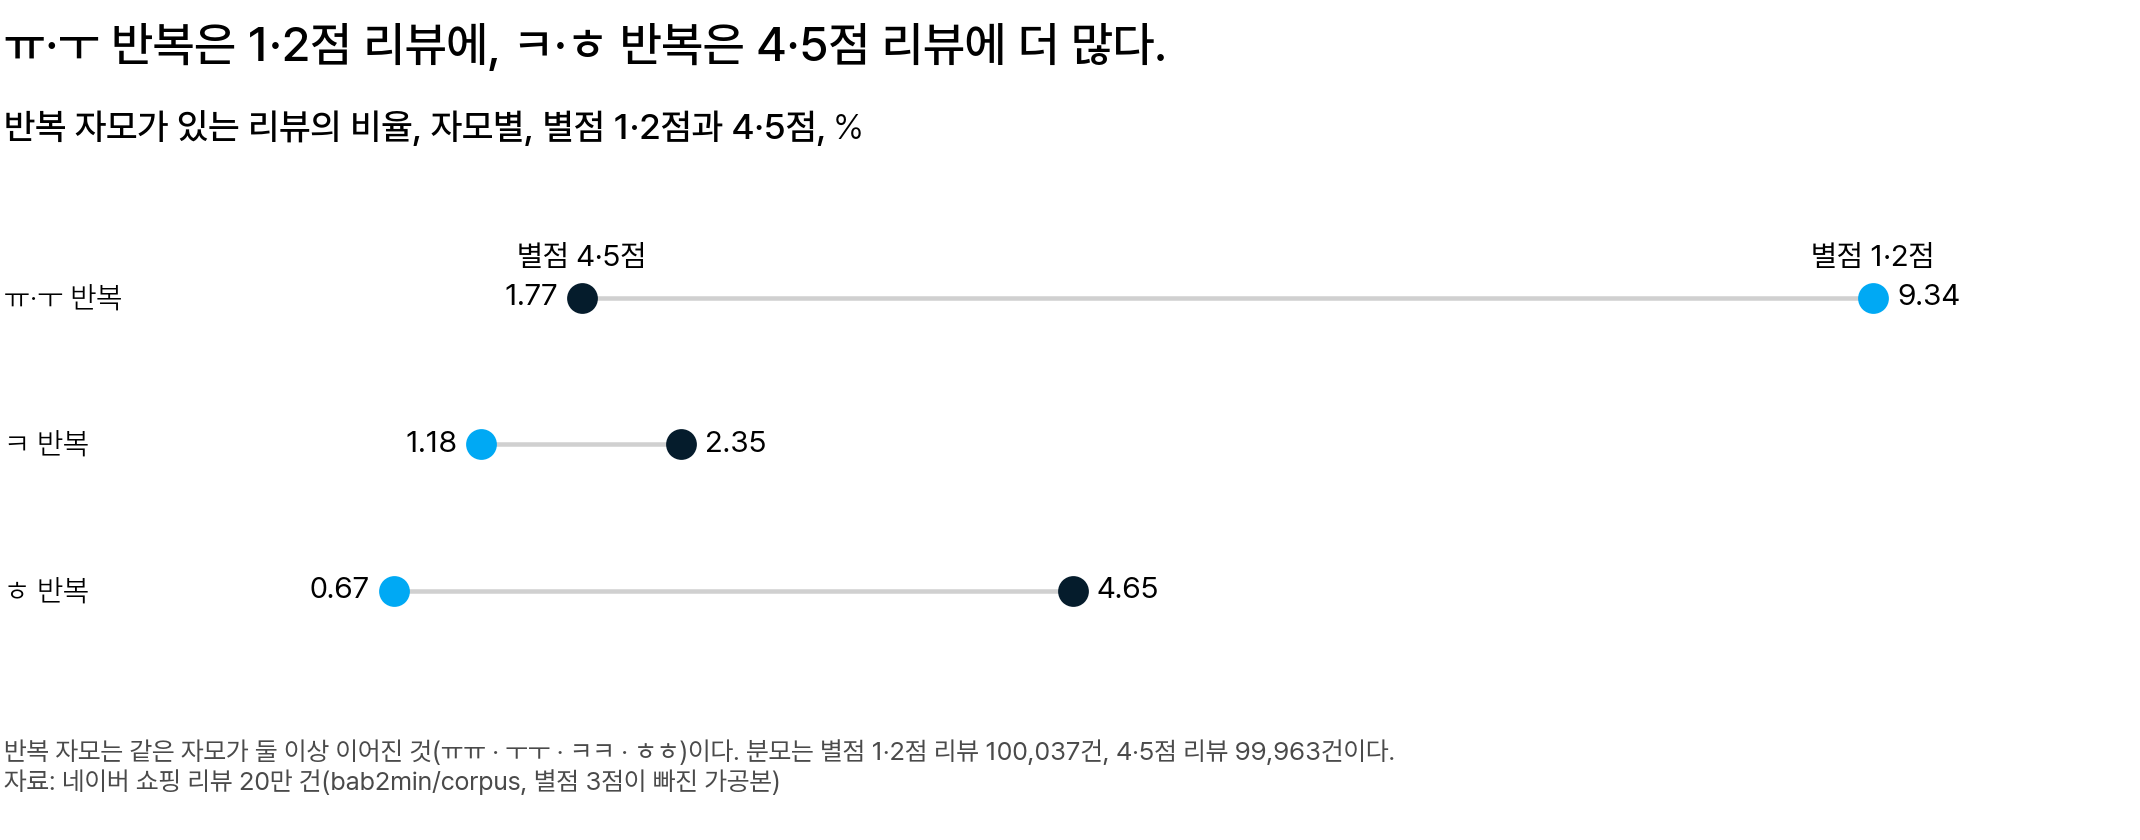

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 반복 자모별 리뷰 비율, 별점 1·2점 대 4·5점. 하늘색 점이 1·2점 리뷰, 남색 점이 4·5점 리뷰다. ㅠ·ㅜ 반복은 1·2점 쪽이 5배 넘게, ㅎ 반복은 4·5점 쪽이 약 7배 많다</em></p>

ㅠ · ㅜ 반복은 별점 1·2점 리뷰에 많고, ㅋ · ㅎ 반복은 반대로 별점이 높은 리뷰에 많습니다. ㅠ · ㅜ 반복 때문에 반복 자모가 있는 리뷰 전체도 별점이 낮은 쪽에서 더 많습니다.

| 별점 | ㅠ · ㅜ 반복 | 반복 자모 전체 |
|---|---:|---:|
| 1·2점 | 9.34% | 13.17% |
| 4·5점 | 1.77% | 8.70% |

다만 그림의 세 자모 비율을 더해도 앞의 전체 비율이 되지 않습니다. 한 리뷰에 여러 자모가 함께 있기도 하고, 그림에 없는 자모를 반복한 리뷰도 있기 때문입니다.

반면 자모 나열은 드뭅니다. 리뷰 20만 건 가운데 427건(0.21%)이고, 아래 별점 2점 리뷰가 그 예입니다.

> 「내구성 약함 입는데ㅇㄷㅇㅈㅇㄷㄱㅌㅅ 찢어짐…」

「ㅇㄷㅇㅈㅇㄷㄱㅌㅅ」에는 서로 다른 자음이 6개(ㅇ · ㄷ · ㅈ · ㄱ · ㅌ · ㅅ) 있습니다.

마지막으로 띄어쓰기 오류는 아래 리뷰 같은 문장입니다.

> 「빠른배송에 좋은가격에 잘 구매할수있었어요」

그래도 형태소 분석기 Kiwi 로 나누면 이 문장의 이어 쓴 어절에서도 배송 · 가격 · 구매 세 명사가 떨어져 나옵니다.

**세 잡음은 각각 어떻게 다룰까요?**

먼저 반복 자모입니다. Kiwi 는 형태소마다 명사 · 동사 · 기호 같은 품사도 함께 정합니다. 「ㅋㅋㅋ」 · 「ㅠㅠ」의 품사는 기호입니다.

이 수업은 명사만 골라 낱말 순위를 구하므로, 반복 자모는 낱말 수에 들어가지 않아 지울 이유가 없습니다. 오히려 지우면 1·2점 리뷰의 ㅠㅠ 도, 4·5점 리뷰에 많은 ㅋㅋ · ㅎㅎ 도 본문에서 사라져 감정의 흔적을 잃습니다. 그래서 반복 자모는 남깁니다.

다만 남겨 두면 기호별 집계가 흐트러집니다. ㅠ 를 몇 번 눌렀는지는 리뷰마다 제각각이라, 별점마다 기호를 집계할 때 ㅠㅠ 와 ㅠㅠㅠㅠㅠ 가 서로 다른 기호가 됩니다. 이 둘을 한 기호로 맞추려고, 셋 이상 이어진 반복 자모는 두 글자로 줄입니다.

자모 나열은 반복 자모와 달리 뜻이 없어, 「ㅇㄷㅇㅈㅇㄷㄱㅌㅅ」을 지워도 잃는 정보가 없습니다. 남겨 두면 기호별로 집계할 때 자판 입력의 모양마다 기호의 가짓수만 하나씩 늘어납니다. 그래서 자모 나열은 지웁니다.

지우기 전에 어느 리뷰에 있었는지 기록해 두면, 나중에 원문으로 잘못 지운 리뷰가 없는지 확인할 수 있습니다. 세 잡음을 다루는 방법을 표 하나로 정리합니다.

| 잡음 | 예 | 다루는 법 | 이유 |
|---|---|---|---|
| 반복 자모 | 「너무 느려요 ㅠㅠㅠㅠㅠ」 | 셋 이상 이어지면 두 글자로 줄여 남긴다 | 뜻이 있는 표시라 남기고, ㅠㅠ 와 ㅠㅠㅠㅠㅠ 를 한 모양으로 맞춘다 |
| 자모 나열 | 「입는데ㅇㄷㅇㅈㅇㄷㄱㅌㅅ」 | 어느 리뷰에 있었는지 기록해 두고, 집계 전에 그 구간을 지운다 | 뜻이 없어 지워도 잃는 정보가 없다. 기록해 두면 잘못 지운 리뷰가 없는지 원문으로 확인할 수 있다 |
| 띄어쓰기 오류 | 「빠른배송에」 | 고치지 않는다 | 형태소로 나누면 이어 쓴 어절에서도 명사가 떨어져 나온다 |

이 표대로 리뷰 20만 건을 정리하면 본문이 바뀐 리뷰는 3,561개입니다.

| 바뀐 이유 | 리뷰 수 |
|---|---:|
| 자모 나열을 지운 리뷰 | 427 |
| 셋 이상 이어진 반복 자모만 줄인 리뷰 | 3,134 |

반면 ㅋㅋ · ㅠㅠ 처럼 두 글자뿐인 반복 자모는 그대로라, 반복 자모가 있는 리뷰 21,872건 대부분은 바뀌지 않습니다.

> 뜻이 있는 반복 자모는 줄여서 남기고, 뜻 없는 자모 나열은 어느 리뷰에 있었는지 기록한 뒤 지웁니다.

**잡음은 코드에서 어떤 순서로 정리하나요?**

아래 셀은 위 표를 코드로 옮긴 것이고 실행은 선택입니다.

- 자모 나열을 먼저 지웁니다.
- 셋 이상 이어진 반복 자모를 두 글자로 줄여 남깁니다.
- 끝으로 공백을 정리합니다. 자모 나열을 지운 곳에는 공백이 겹치거나 문장 끝에 공백이 남을 수 있기 때문입니다.

띄어쓰기는 고치지 않으므로 띄어쓰기를 다루는 코드는 없습니다. 공백 정리는 겹친 공백만 하나로 줄이므로 이어 쓴 어절은 그대로 남습니다. ▶ 로 실행하면 세 문장이 어떻게 바뀌는지 나옵니다.

In [ ]:
# 정리 순서: 자모 나열 지우기 → 반복 자모 두 글자로 → 지운 곳에 남은 공백 정리
import re

JAMO_RUN = re.compile(r"[ㄱ-ㅣㆍ]{4,}")        # 자모만 넷 이상 이어진 구간(자모 나열 후보)


def n_consonants(run):
    return len(set(re.findall(r"[ㄱ-ㅎ]", run)))   # 구간 안의 서로 다른 자음 수


def clean_review(text):
    text = JAMO_RUN.sub(lambda m: "" if n_consonants(m.group()) >= 4 else m.group(), text)
    text = re.sub(r"([ㄱ-ㅎㅏ-ㅣ])\1{2,}", r"\1\1", text)   # 셋 이상 이어진 같은 자모 → 두 글자
    return re.sub(r"\s{2,}", " ", text).strip()


for s in ["ㅋㅋㅋㅋ 배송 빨라요", "너무 느려요 ㅠㅠㅠㅠㅠ", "내구성 약함 입는데ㅇㄷㅇㅈㅇㄷㄱㅌㅅ 찢어짐"]:
    print(f"{s}\n  → {clean_review(s)}")

- 첫 문장의 「ㅋㅋㅋㅋ」는 자모 4개가 이어졌지만 자음이 ㅋ 하나라 자모 나열이 아닙니다. 그래서 반복 자모로 처리되어 「ㅋㅋ」로 줄어듭니다.
- 둘째 문장의 「ㅠㅠㅠㅠㅠ」도 같은 식으로 「ㅠㅠ」가 됩니다.
- 셋째 문장은 앞에서 본 별점 2점 리뷰입니다. 이 문장의 자모 구간은 서로 다른 자음이 6개라 지워지고 「내구성 약함 입는데 찢어짐」이 남습니다.

<details class="lms-extra"><summary>더 깊이 — 숫자를 지우지 않는 이유</summary>

텍스트 정리 예제에는 숫자를 모두 `<NUM>` 같은 한 기호로 바꾸는 처리가 자주 나옵니다. 어휘가 줄어 집계가 단순해지기 때문입니다.

그런데 민원 제목에서는 숫자가 분석 정보인 경우가 많습니다. 예를 들어 「7일 이내」는 청약철회 기간이고 「30만 원」은 피해 금액입니다. 모든 숫자를 한 기호로 바꾸면 기간을 말한 민원과 금액을 말한 민원을 나눠 건수를 구할 수 없게 됩니다.

그래서 정리 방법을 정할 때는 무엇을 지우면 무엇을 잃는지를 먼저 묻습니다. 반복 자모를 지우지 않고 줄인 것도 같은 물음의 답입니다.

</details>

<div class="lms-summary">

**정리**

잡음마다 지우면 잃는 정보가 있는지, 남기면 기호별 집계가 흐트러지는지를 물어 다루는 법을 정합니다. 반복 자모는 별점마다 비율이 다른 표시라 줄여서 남기고 뜻 없는 자모 나열만 지웁니다.

**할 일**

- 반복 자모는 셋 이상 이어지면 두 글자로 줄여 남깁니다
- 자모 나열은 어느 리뷰에 있었는지 기록해 두고 지웁니다
- 띄어쓰기는 고치지 않고 형태소로 나눠 집계합니다

이렇게 정리하면 리뷰 20만 건 가운데 본문이 바뀐 리뷰는 3,561개입니다.

</div>

> **[문제] 별점 2점 리뷰 「내구성 약함 입는데ㅇㄷㅇㅈㅇㄷㄱㅌㅅ 찢어짐…」의 자모 구간은 잡음 정리에서 어떻게 다루는가?**
>
> 1. 반복 자모이므로 두 글자로 줄여 「ㅇㄷ」만 남긴다
> 2. 자모 나열이 있던 리뷰를 기록해 두고, 그 구간을 지운 뒤 집계한다
> 3. 불만 리뷰의 흔적이므로 그대로 둔 채 집계한다

## 3. 어절 · 형태소 · 품사 선택

민원 제목을 어디서 자르고 어떤 품사를 남겨야 「환불」을 쓴 제목을 빠짐없이 찾고 상위 낱말로 무엇에 대한 글인지 알 수 있을까요?

### 왜 형태소로 자르는가 [필수]

「무엇을 말하는가」에 답하려면 글을 토큰으로 잘라 토큰마다 개수를 구합니다. 앞에서 본 영어 문장처럼, 자르는 기준이 바뀌면 토큰도 바뀝니다.

**어절과 형태소는 무엇이 다른가요?**

공백으로 자른 단위를 **어절**이라 하고 뜻을 가진 가장 작은 단위를 **형태소(morpheme)** 라고 합니다. 예를 들어 「환불요청했는데」는 어절로는 하나이고 형태소로는 환불 · 요청 · 하 · 었 · 는데 5개입니다. 「했」 한 글자에는 「하(동사를 만드는 접미사)」와 지난 일을 나타내는 「었」 두 형태소가 함께 있습니다.

그런데 한국어는 자르는 기준에 따른 차이가 더 큽니다. 조사와 어미가 낱말 바로 뒤에 오는 말이라, 공백으로 자르면 같은 낱말이 여러 어절로 흩어지기 때문입니다. 그래서 토큰은 늘 「어절 토큰」 · 「형태소 토큰」처럼 자른 방식과 함께 부릅니다.

**공백으로 자르면 같은 낱말이 얼마나 흩어지나요?**

민원 제목에서 이 차이가 얼마나 큰지 「해지」로 확인합니다. 민원 제목 499,844건을 공백으로 자르면 「해지」를 포함한 어절이 **3,358가지** 나옵니다. 아래 표는 그 가운데 6가지의 제목 수입니다.

| 어절 | 제목 수 |
|---|---:|
| 해지 | 19,000 |
| 계약해지 | 8,930 |
| 해지시 | 5,315 |
| 중도해지 | 3,424 |
| 해지요청 | 896 |
| 해지를 | 505 |

공백으로 자른 어절이 낱말과 똑같은 경우만 집계하는 것을 **어절 일치**라고 하겠습니다. 어절 일치로는 3,358가지 가운데 「해지」 하나만 포함되고 나머지 3,357가지는 모두 빠집니다. 그래서 「해지」를 빠짐없이 찾으려면 어절 안에서 형태소를 떼어 내야 합니다.

**형태소 분석기로 나누면 무엇이 나오나요?**

어절 안에서 형태소를 떼어 내는 도구를 **형태소 분석기**라고 하고, 형태소마다 품사도 함께 표시합니다. 여기서는 Kiwi(파이썬 패키지 kiwipiepy, 버전 0.23.1)를 기본 사전 그대로 씁니다. 「환불요청했는데 답이 없어요」는 Kiwi 로 이렇게 나뉩니다.

```text
환불/NNG 요청/NNG 하/XSV 었/EP 는데/EC 답/NNG 이/JKS 없/VA 어요/EF
```

공백으로는 어절 토큰 3개이고 형태소로는 형태소 토큰 9개입니다. 토큰마다 빗금 뒤의 기호가 품사입니다. 예를 들어 NNG 는 일반 명사, VA 는 형용사, JKS 는 조사입니다.

**형태소 경계는 늘 글자 사이에 있나요?**

형태소 경계가 늘 글자 사이에 있는 것은 아닙니다. 어절 토큰 4개인 「배송은 빠른데 바느질이 엉성해요」를 Kiwi 로 자르면 형태소 토큰은 9개입니다.

| 어절 토큰 | 배송은 | 빠른데 | 바느질이 | 엉성해요 |
|---|---|---|---|---|
| 형태소 토큰 | 배송 · 은 | 빠르 · ᆫ데 | 바느질 · 이 | 엉성 · 하 · 어요 |

앞의 어절 3개는 형태소 토큰 2개씩으로, 「엉성해요」는 3개로 나뉘어 2 + 2 + 2 + 3 = 9 입니다. 이 가운데 두 경계는 한 글자 안에 있습니다.

- 「빠른데」의 「른」에는 빠르 + ᆫ데가 함께 들어 있습니다.
- 「엉성해요」의 「해」에는 하 + 어요가 함께 들어 있습니다.

「환불요청했는데」의 「했」(하 + 었)과 같은 경우입니다. 그래서 글자 사이를 끊는 방법으로는 이런 경계를 찾을 수 없습니다.

> 한국어는 공백이나 글자 사이를 끊는 방법 대신 형태소 분석기로 자릅니다.

<details class="lms-extra"><summary>자세히 — Kiwi 품사 기호표</summary>

Kiwi 의 품사 기호는 앞 글자로 크게 나뉩니다. 앞 글자가 N 이면 명사, V 면 용언, J 면 조사, E 면 어미라고 읽으면 대부분 맞습니다. 아래 예는 모두 이 수업의 예문에서 가져왔습니다.

| 기호 | 뜻 | 예 |
|---|---|---|
| NNG | 일반 명사 | 환불, 요청, 답, 배송 |
| NNP | 고유 명사 | 우한 |
| NNB | 의존 명사 | 수(구매할수) |
| VV | 동사 | 쓰(쓰다), 사(사다) |
| VA | 형용사 | 없(없어요), 좋(좋아요), 빠르(빠른) |
| VX | 보조 용언 | 않(좋지 않아요) |
| XR | 어근 | 엉성(엉성해요) |
| XSV·XSA·XSN | 동사·형용사·명사를 만드는 접미사 | 하(요청했는데), 하(엉성해요), 권(항공권) |
| JKS·JKB·JX | 조사(주격·부사격·보조사) | 이(답이), 에(배송에), 은(배송은) |
| EP·EC·EF·ETM | 어미(선어말·연결·종결·관형형) | 었, 는데, 어요, ᆫ데(빠른데) |
| MAG | 일반 부사 | 잘, 너무 |
| SW | 기타 기호 | ㅋㅋㅋ, ㅠㅠ |

</details>

<details class="lms-extra"><summary>더 깊이 — Hugging Face 토크나이저가 텍스트를 자르는 4단계</summary>

Hugging Face 의 토크나이저(tokenizer, 텍스트를 토큰으로 자르는 도구)도 텍스트를 4단계에 걸쳐 토큰으로 자릅니다.

<img src="https://huggingface.co/datasets/huggingface-course/documentation-images/resolve/main/en/chapter6/tokenization_pipeline.svg" alt="정규화·사전 토큰화·모델·후처리 4단계로 문장을 자르는 과정" width="620"/>
<p align="center"><em>▲ 영어 문장 「Hello how are U tday?」가 정규화(소문자로) → 사전 토큰화(공백·구두점) → 모델(더 작은 단위) → 후처리(앞뒤 특수 토큰) 4단계를 거친다 (출처: Hugging Face LLM Course 6장, Apache-2.0)</em></p>

이 수업에서 한 일과 비교하면, 「2. 고객 글의 잡음」에서 한 잡음 정리가 첫 단계인 정규화(Normalization)에 해당합니다. 공백 자르기와 형태소 자르기는 둘째 단계인 사전 토큰화(pre-tokenization)에 해당합니다. 여기서 「사전」은 「미리」라는 뜻으로, 본 자르기 앞에 공백 · 구두점으로 미리 자르는 단계입니다. 사용자 사전의 「사전」과는 다른 말입니다.

셋째 단계의 「##ay」 같은 토큰은 서브워드 토큰입니다. 낱말을 더 작은 단위로 자르는 방식이고 여기서는 이름만 소개합니다.

<img src="https://huggingface.co/datasets/huggingface-course/documentation-images/resolve/main/en/chapter2/character_based_tokenization.svg" alt="영어 문장을 글자 하나씩 자른 토큰" width="760"/>
<p align="center"><em>▲ 같은 문장을 글자 하나씩 자른 토큰. 어휘는 알파벳과 기호 몇십 개로 작아지지만 토큰 수는 글자 수만큼 많아진다 (출처: Hugging Face LLM Course 2장, Apache-2.0)</em></p>

글자 단위로 자르면 사전에 없는 낱말이 생기지 않습니다. 하지만 토큰 하나가 가진 뜻이 거의 없습니다. 형태소와 서브워드는 공백 자르기와 글자 자르기 사이에서 자르는 방식입니다.

</details>

### 문서 비율이란 무엇인가 [필수]

어절로 자르느냐 형태소로 자르느냐에 따라 「환불」을 쓴 제목 수는 얼마나 달라질까요? 비교하려면 먼저 무엇을 한 건으로 계산할지 정해야 합니다.

**문서 수와 문서 비율은 어떻게 구하나요?**

여기서는 낱말마다 그 말을 쓴 문서가 몇 건인지 구합니다. 문서는 민원 제목 한 건이고 리뷰를 다룰 때는 리뷰 한 건입니다.

이 건수를 문서 수라고 하고 영어로는 document frequency(df)라고 합니다. 아래 식에서는 $d_w$ 로 나타냅니다. **문서 비율**은 df 를 전체 문서 수 $N$ 으로 나눈 값입니다.

> 한 문서에 같은 말이 몇 번 나오든, 그 문서는 한 건으로 계산합니다.

$$
\hat p_w = \frac{d_w}{N}
$$

- $\hat p_w$: 낱말 $w$ 의 문서 비율
- $d_w$: 낱말 $w$ 를 쓴 문서 수(df)
- $N$: 전체 문서 수

문서 비율은 0 에서 1 사이의 값입니다.

| $\hat p_w$ | 뜻 |
|---|---|
| 0 | 어느 문서도 $w$ 를 쓰지 않음 |
| 0.17 | 문서 100건 가운데 약 17건이 $w$ 를 씀 |
| 1 | 모든 문서가 $w$ 를 씀 |

**민원 세 건으로 구하면 어떻게 되나요?**

민원 세 건의 제목에서 Kiwi 가 나눈 일반 · 고유 명사를 품목명 · 제목 옆에 모았습니다.

| `품목명` | `사건제목` | `명사` |
|---|---|---|
| 항공여객운송서비스 | 마일리지 사용 제한 | 마일리지, 사용, 제한 |
| 샴푸 | 샴푸 배송지연 환불지연건 | 샴푸, 배송, 지연, 환불, 지연 |
| 셔츠 | 배송지연된 물품 환불요청 | 배송, 지연, 물품, 환불, 요청 |

어절 「환불지연건」 · 「환불요청」에서도 명사 「환불」이 떨어져 나옵니다. 그래서 세 건 가운데 둘째 · 셋째 제목이 「환불」의 문서 수에 들어가고 「환불」의 문서 비율은 2 ÷ 3 ≈ 0.67 입니다.

또 둘째 제목은 「지연」을 두 번 썼지만 「지연」의 문서 수에는 한 건으로 들어갑니다. 같은 제목의 「건」은 Kiwi 가 의존 명사(NNB)로 나눠 명사 목록에 들어가지 않습니다.

**실제 민원에서는 두 방식이 얼마나 다른가요?**

형태소 분석을 노트북에서 바로 실행할 수 있도록, 민원 제목 50만 건에서 무작위로 고른 2만 건을 씁니다. 시드를 0 으로 고정해서 누가 실행해도 같은 2만 건이 나옵니다. 실습에서도 이 표본으로 같은 계산을 합니다.

| 집계 방식 | $d_w$ | $N$ | $\hat p_w$ |
|---|---:|---:|---:|
| 공백 어절이 「환불」과 똑같다 | 2,096 | 20,000 | 10.48% |
| Kiwi 형태소 명사에 「환불」이 있다 | 3,550 | 20,000 | 17.75% |

형태소 쪽을 식에 대입하면 $\hat p_w = 3{,}550 \div 20{,}000 = 0.1775$ 입니다. 반면 어절 기준으로는 「환불요청」 · 「환불을」이 빠져, 문서 비율이 17.75 − 10.48 = 7.27%p 낮게 나옵니다. 그래서 민원 키워드의 문서 비율은 어절보다 형태소로 구합니다.

### 사용자 사전 [필수]

형태소 분석에도 한계가 있습니다. Kiwi 기본 사전은 사전에 없는 복합어를 쪼갭니다.

| 원문 | Kiwi 기본 사전의 분석 |
|---|---|
| 항공권 | 항공/NNG + 권/XSN |
| 택배사 | 택배/NNG + 사/NNG |
| 우한폐렴 | 우한/NNP + 폐렴/NNG |
| 취소수수료 | 취소/NNG + 수수료/NNG |

표의 「항공권」은 명사 목록에 「항공」만 남아, 항공권 환불 민원이 「항공」으로만 집계됩니다. 또 「가루다항공」 같은 항공사 이름도 가루다 + 항공으로 나뉩니다. 그래서 「항공」의 문서 수에는 항공권이 아닌 제목도 포함되어, 항공권 민원만의 문서 수를 구할 수 없습니다.

이런 복합어를 분석기에 한 낱말로 더해 주는 목록을 **사용자 사전(user dictionary)** 이라고 합니다. Kiwi 에서는 `add_user_word("항공권", "NNG")` 를 실행하면 「항공권」이 명사 하나가 됩니다.

**사용자 사전에 더하면 무엇이 바뀌나요?**

사용자 사전에 낱말을 더하면 다른 낱말의 문서 수도 바뀝니다. 예를 들어 「취소수수료」를 한 낱말로 더하면 민원 제목 50만 건에서 「취소」의 문서 수가 줄어듭니다.

| 사용자 사전 | 문서 수 |
|---|---:|
| 더하기 전 | 50,016 |
| 더한 뒤 | 49,484 |

「취소」가 「취소수수료」 안에만 있던 제목 532건에서 「취소」가 따로 집계되지 않기 때문입니다. 따라서 사용자 사전은 더하기 전과 뒤의 표를 비교하며 쓰고 과제에서 이 비교를 직접 합니다.

> **[문제] 민원 제목을 공백 어절 일치로 집계하면 「환불요청」 · 「환불을」이 빠져, 「환불」의 문서 비율이 형태소로 구한 값보다 낮게 나온다.**
>
> 1. O (맞다)
> 2. X (틀리다)

### 품사 선택: 무엇을 남기는가 [필수]

형태소로 자른 뒤에도 정할 것이 하나 남습니다. 「환불요청했는데 답이 없어요」의 형태소 토큰 9개 가운데 「었」 · 「는데」 · 「어요」에는 무엇에 대한 글인지가 없기 때문입니다.

**품사 선택은 어떤 두 방식으로 하나요?**

문서 비율을 구하기 전에 어떤 품사의 형태소를 남길지 정합니다. 이 일을 **품사 선택**이라고 하고 여기서는 두 방식을 씁니다.

- **명사만**: 일반 명사(NNG)와 고유 명사(NNP)만 남깁니다. 위 문장에서는 환불 · 요청 · 답입니다.
- **명사 + 용언**: 명사에 동사(VV) · 형용사(VA)를 더합니다. 위 문장에서는 환불 · 요청 · 답 · 없다입니다.

동사와 형용사를 함께 **용언**이라고 부릅니다. 용언은 「없어요」 · 「없는데」처럼 끝이 바뀝니다. 바뀌는 끝을 떼고 남는 앞부분 「없」을 **어간**이라 하고 어간에 「다」를 더한 「없다」 하나로 집계합니다.

**리뷰에서는 두 방식을 어떻게 비교하나요?**

두 방식의 차이는 리뷰에서 확인합니다.

- 리뷰 별점 1·2점에서 무작위로 1만 건을 고릅니다.
- 자모 나열은 지우고 반복 자모는 두 글자로 줄입니다.
- 두 방식으로 문서 비율 상위 10 을 구해 비교합니다.

명사만 남길 때와 비교하면, 명사 + 용언의 상위 10 가운데 8개가 바뀝니다. 두 방식에 함께 있는 낱말은 배송 · 구매 둘뿐입니다. 아래 그림은 두 방식의 상위 10 을 문서 비율과 함께 나란히 보여 줍니다.

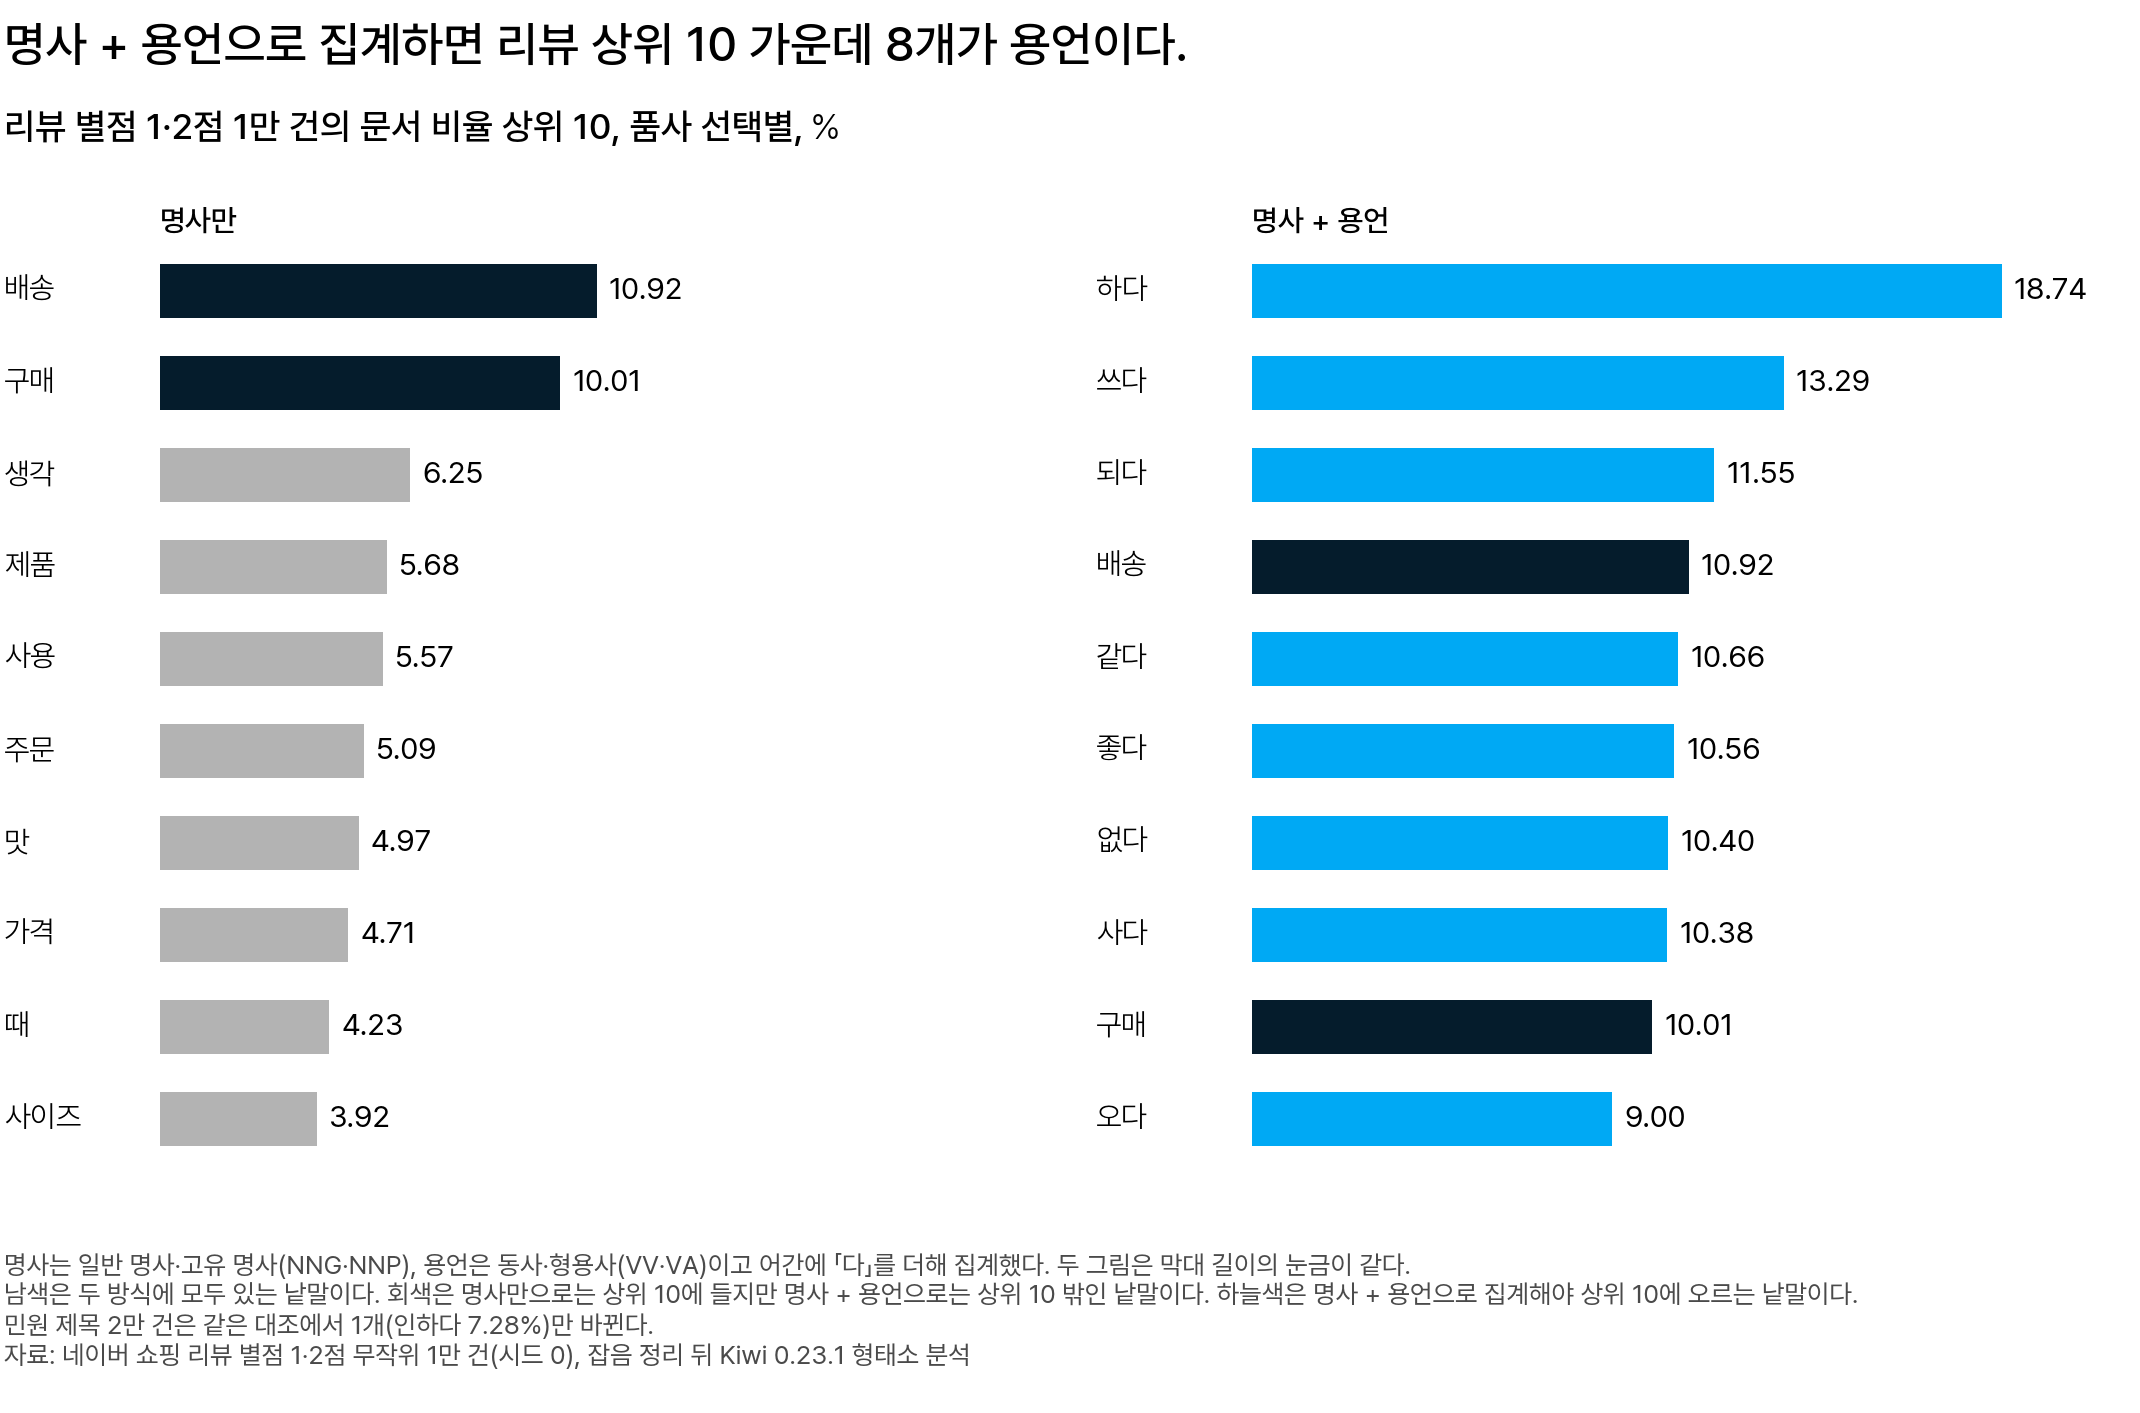

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 리뷰 별점 1·2점 1만 건의 문서 비율 상위 10. 왼쪽은 명사만, 오른쪽은 명사 + 용언이다. 남색은 두 그림에 함께 있는 낱말이다. 회색은 명사만으로는 상위 10 에 들지만 명사 + 용언으로는 상위 10 밖인 낱말이다. 하늘색은 명사 + 용언에서만 상위 10 에 드는 낱말이다</em></p>

막대 하나가 낱말 하나이고 막대 길이가 그 낱말을 쓴 리뷰의 비율입니다. 오른쪽 1위 「하다」의 막대는 18.74% 로, 왼쪽 1위 「배송」의 10.92% 보다 깁니다.

18.74% 는 「추천안해요」처럼 동사 하(VV)가 있는 리뷰의 비율입니다. 「해요」는 하/VV 어요/EF 로 나뉘고 어간 하가 「하다」로 집계됩니다. 반면 「환불요청했는데」의 하(XSV)처럼 명사 뒤에 이어진 접미사는 포함하지 않습니다.

그런데 막대가 길어도 「하다」에는 무엇에 대한 불만인지가 없고 쓰다 · 되다 · 사다 · 오다도 마찬가지입니다.

| 구분 | 명사만 | 명사 + 용언 |
|---|---|---|
| 남기는 품사 | 일반 · 고유 명사(NNG · NNP) | 명사와 동사 · 형용사(VV · VA) |
| 좋은 점 | 상위 10 대부분이 배송 · 구매 · 제품 같은 대상 이름 | 「없다」(10.40%)처럼 상태를 나타낸 리뷰도 포함함 |
| 약한 점 | 「없다」 · 「좋다」 같은 상태는 빠짐 | 상위 10 가운데 8개가 용언이고, 1위 하다에는 대상이 없음 |
| 이럴 때 쓴다 | 「무엇을 말하는가」에 답할 때 | 「없다」처럼 상태를 나타낸 리뷰가 몇 건인지 볼 때(원문과 함께) |

**민원 제목에서도 결과가 달라지나요?**

민원 제목 표본 2만 건에 같은 비교를 하면 상위 10 에서 1개만 바뀝니다. 「반품」 대신 「인하다」(7.28%)가 들어옵니다.

제목 「코로나로 인한 숙박취소」의 「인한」이 인하(VV)로 나뉘어 「인하다」로 집계된 것입니다. 요약된 제목은 명사 위주라 품사 선택을 바꿔도 상위 10 이 거의 그대로입니다.

**용언을 남기면 무엇을 조심해야 하나요?**

리뷰에서는 명사 + 용언의 약한 점이 하나 더 있습니다. 「좋다」가 별점 1·2점 리뷰의 10.56%(1,056건)에도 나옵니다.

Kiwi 는 「좋지 않아요」를 좋/VA 지/EC 않/VX 어요/EF 로 나누고 보조 용언(VX) 「않」은 남기지 않습니다. 그래서 「좋지 않아요」와 「좋아요」가 똑같이 「좋다」 하나가 됩니다.

「좋은데」 · 「좋지만」처럼 대비로 쓴 리뷰도 함께 포함되어, 어떤 쓰임인지는 원문을 읽어야 압니다. 그래서 용언까지 포함한 표는 원문을 읽기 전에 만족 · 불만의 비율로 해석하지 않습니다.

> 「무엇을 말하는가」에 답할 때는 명사만 남깁니다.

<div class="lms-summary">

**정리**

집계 대상은 어디서 자를지(어절 · 형태소)와 어떤 품사를 남길지로 정해지고 둘 다 순위를 바꿉니다. 어절로 자르면 다른 말과 이어 쓴 낱말이 빠지고 용언까지 남기면 대상을 알 수 없는 낱말이 상위에 옵니다.

**할 일**

- 민원 키워드는 Kiwi 형태소로 잘라 명사(NNG · NNP)만 남기고 낱말마다 문서 비율을 구합니다
- 형태소 기준 표를 만든 뒤 원문 몇 건을 읽어 쪼개진 복합어와 낱말의 쓰임을 확인합니다
- 쪼개진 복합어는 사용자 사전에 더하고, 더하기 전과 뒤의 표를 비교합니다

표본 2만 건의 「환불」은 어절 기준 10.48%, 형태소 명사 기준 17.75% 입니다.

</div>

> **[문제] 자르는 방식과 토큰 수**
>
> 딥러닝 시계열에서 28일은 하루를 토큰으로 쓰면 28개, 7일 패치로 자르면 4개였습니다. 「배송은 빠른데 바느질이 엉성해요」는 어절 토큰과 형태소 토큰으로 각각 몇 개인지 구해 보세요. 두 경우에 공통인 점을 한 문장으로 쓰고, 토큰 수를 비교하려면 무엇을 알아야 하는지도 적어 보세요.

## 4. 문서-단어 행렬

수만 건의 형태소 목록을 어떤 표로 바꿔야 문서끼리 비교하고 열마다 더할 수 있을까요?

### 문서-단어 행렬이란 무엇인가 [필수]

형태소로 자르고 명사만 남기면 문서마다 낱말 목록이 하나씩 생깁니다. 그런데 이 목록은 문서마다 길이와 순서가 달라, 그대로는 문서끼리 비교할 수 없습니다.

그래서 모든 문서를 열이 같은 표 하나로 옮깁니다. 이 표를 **문서-단어 행렬(document-term matrix, DTM)** 이라고 합니다.

> 문서-단어 행렬은 문서 하나가 행 하나, 낱말 하나가 열 하나인 표입니다. 셀 하나는 그 문서에서 그 낱말이 나온 횟수입니다.

문서를 낱말이 들어 있는 가방처럼 보고 낱말별 횟수만 남긴다는 뜻에서, 이 표를 bag-of-words(단어 가방)라고도 합니다. 여기서 열로 쓰는 낱말 전체를 **어휘(vocabulary)** 라고 합니다.

이렇게 텍스트를 수의 벡터로 바꾸는 일을 **벡터화(vectorization)** 라고 합니다. 문서-단어 행렬이 그 가장 기본적인 방법입니다. 셀 하나는 기호로 이렇게 씁니다.

$$
x_{i,w}
$$

- $x_{i,w}$: 문서 $i$ 에서 낱말 $w$ 가 나온 횟수
- $i$: 문서 번호(행)
- $w$: 어휘의 낱말(열)
- $V$: 어휘 크기(열의 수)

문서 $i$ 의 행은 셀 $V$ 개를 어휘 순서대로 나열한 벡터입니다.

**작은 예시에서는 행렬을 어떻게 채우나요?**

작은 예시로 확인합니다. 아래 문서 3개는 낱말 사이를 공백으로 띄웠습니다.

| 문서 | 낱말 |
|---|---|
| 문서 1 | 배송 빠름 만족 |
| 문서 2 | 배송 늦음 환불 |
| 문서 3 | 환불 요청 환불 |

이 문서들의 낱말 6가지를 가나다순으로 나열한 [늦음 만족 배송 빠름 요청 환불]이 어휘입니다. 어휘 크기는 $V = 6$ 입니다. 문서가 3개이므로 이 문서-단어 행렬은 3행 6열이고 셀은 18개입니다.

행렬은 문서마다 낱말을 앞에서부터 하나씩 읽으며 채웁니다. 낱말이 나올 때마다 그 문서에서 그 낱말의 셀에 1 을 더합니다. 문서 3 「환불 요청 환불」은 아래 차례로 채웁니다.

- 첫 환불과 요청의 셀에 1 씩 더합니다.
- 두 번째 환불에서 환불의 셀에 1 을 다시 더해 2 가 됩니다.

같은 낱말이 다시 나오면 새 열을 만들지 않고 같은 셀에 1 을 더할 뿐입니다. 그래서 문서 3 을 「요청 환불 환불」로 바꿔 써도 이 문서의 행은 [0 0 0 0 1 2] 그대로입니다. 열은 어휘의 가나다순이라 낱말이 나온 차례는 남지 않습니다.

아래 셀은 세 문서를 이 방법대로 집계해 행렬을 만듭니다. `pd.crosstab` 은 두 열의 값이 짝지어 나온 횟수를 표로 만드는 pandas 함수입니다. (문서, 낱말) 쌍 하나가 토큰 하나라서, 그 횟수가 바로 셀 값이 됩니다.

In [ ]:
# 작은 예시 문서 3개로 문서-단어 행렬을 만듭니다
import pandas as pd

docs = {"문서 1": "배송 빠름 만족", "문서 2": "배송 늦음 환불", "문서 3": "환불 요청 환불"}
pairs = [(name, word) for name, text in docs.items() for word in text.split()]   # (문서, 낱말) 쌍 하나가 토큰 하나
tokens = pd.DataFrame(pairs, columns=["문서", "낱말"])
dtm = pd.crosstab(tokens["문서"], tokens["낱말"])   # 문서마다 낱말이 나온 횟수, 열은 가나다순

print("행렬 크기(행, 열):", dtm.shape, "· 0 인 셀:", int((dtm == 0).sum().sum()), "/", dtm.size)
print("열(어휘, 가나다순):", " · ".join(dtm.columns))
for name, row in dtm.iterrows():                    # 행 하나 = 문서 하나의 벡터
    print(f"{name}: {row.values}")

행렬은 문서 3개 × 낱말 6개라 셀이 18개이고, 그 가운데 0 인 셀이 10개입니다. 문서 1 · 2 는 서로 다른 낱말을 3개씩, 문서 3 은 2개를 써서 0 이 아닌 셀이 3 + 3 + 2 = 8개이기 때문입니다. 문서 3 의 행은 앞에서 직접 채운 [0 0 0 0 1 2] 와 같습니다.

**One-Hot 과는 어떻게 이어지나요?**

문서-단어 행렬의 행 하나는 데이터 랭글링 과목의 One-Hot 과 이어집니다. One-Hot 은 범주 한 값을 한 열만 1 인 행으로 바꿨습니다(`pd.get_dummies`).

문서의 낱말마다 그 One-Hot 행을 만들어 더하면 그 문서의 행이 됩니다. 예를 들어 「환불 요청 환불」은 환불 행 [0 0 0 0 0 1] 둘과 요청 행 [0 0 0 0 1 0] 하나를 더한 [0 0 0 0 1 2] 입니다.

**더하면 무엇이 사라지나요?**

더하면 순서가 사라지고 부정이 어느 낱말에 걸리는지도 함께 사라집니다. 예를 들어 보조 용언 「않다」까지 열로 남긴 어휘가 [늦다 않다 좋다] 라고 하겠습니다. 그러면 뜻이 반대인 두 문장의 행이 같아집니다.

| 문장 | 뜻 | 늦다 | 않다 | 좋다 |
|---|---|---:|---:|---:|
| 늦지 않고 좋아요 | 칭찬 | 1 | 1 | 1 |
| 좋지 않고 늦어요 | 불만 | 1 | 1 | 1 |

「늦지 않고 좋아요」의 「않다」는 「늦다」를, 「좋지 않고 늦어요」의 「않다」는 「좋다」를 부정합니다. 하지만 행에는 세 낱말이 한 번씩 나왔다는 것만 남습니다.

> 문서-단어 행렬에 남는 것은 무엇이 몇 번 나왔는지뿐입니다.

### 셀 대부분이 0 인 행렬: 희소 행렬 [필수]

**실제 행렬은 얼마나 비어 있나요?**

작은 예시는 18셀 가운데 10셀(56%)이 0 이었습니다. 실제 민원 제목으로 문서-단어 행렬을 만들면 0 인 셀의 비율이 이보다 큽니다.

민원 제목 499,844건의 명사 어휘는 30,798종입니다. 그에 비해 제목 하나에 나오는 명사 토큰은 반복까지 포함해 평균 6.145개입니다. 반복된 명사는 셀 하나에 모이므로, 한 행의 30,798셀 가운데 0 이 아닌 셀은 평균 6.04개입니다.

행렬 전체로 보면 0 이 아닌 셀은 0.02% 이고 나머지 99.98% 가 0 입니다. 셀 1만 개로 치면 약 2개입니다.

이런 행렬을 0 인 셀까지 모두 저장하면 Colab 메모리에 들어가지 않습니다. 그래서 **희소 행렬(sparse matrix)** 로 저장합니다.

> 희소 행렬은 0 이 아닌 셀의 위치와 값만 저장하는 표입니다.

실제 크기의 행렬은 위 코드의 `pd.crosstab` 대신 scikit-learn 의 `CountVectorizer` 로 만듭니다. `CountVectorizer` 는 문서 목록을 받아 처음부터 희소 행렬로 만듭니다.

**낱말은 얼마나 드물게 나오나요?**

낱말 대부분이 드물어서 0 인 셀이 이렇게 많습니다. 아래 그림은 명사 30,798종을 문서 수가 큰 순서로 나열한 것입니다.

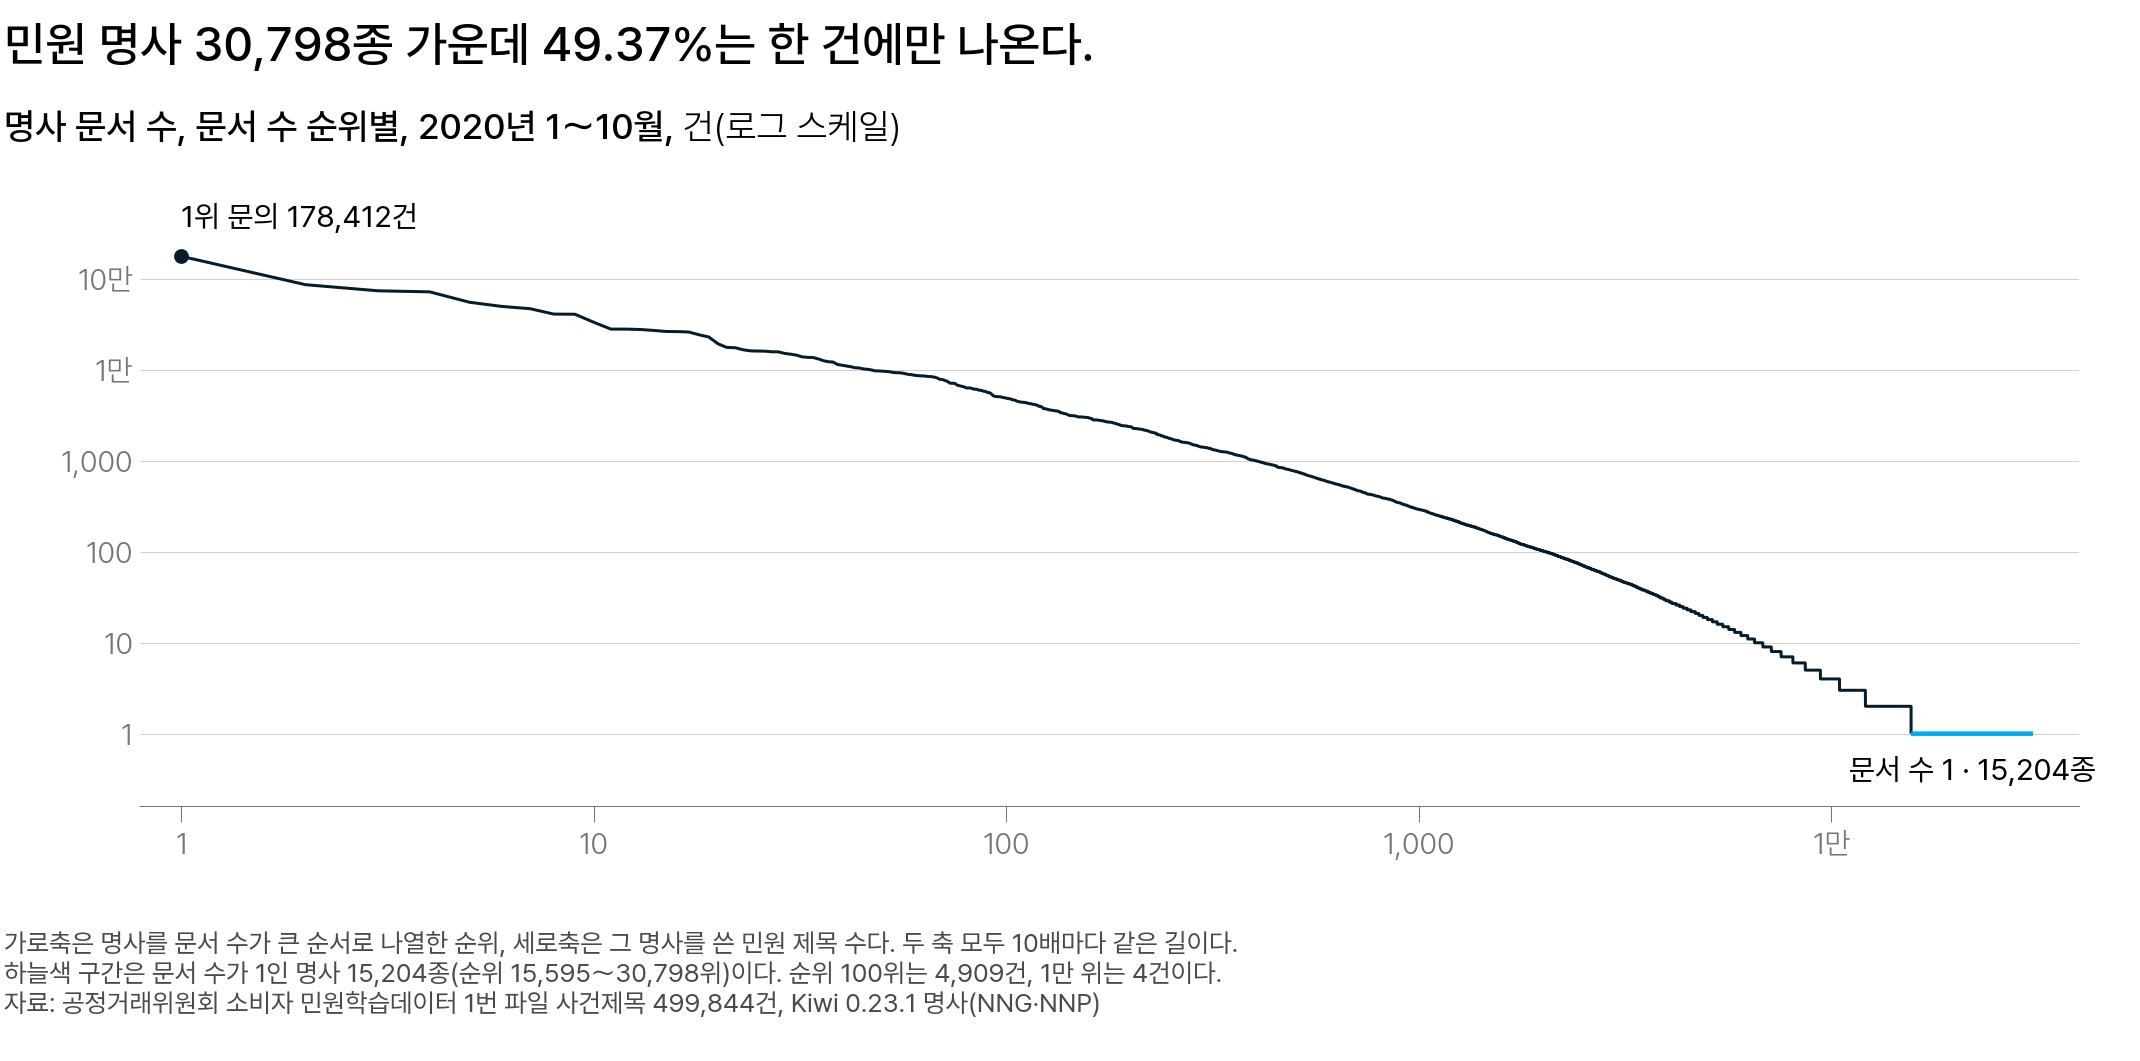

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 민원 명사 30,798종의 순위와 문서 수, 가로축·세로축 모두 로그 스케일. 1위 「문의」는 178,412건이고 오른쪽 끝 하늘색 구간의 15,204종(49.37%)은 한 건에만 나온다</em></p>

- 가로축은 명사의 순위입니다.
- 세로축은 그 명사를 쓴 제목 수(문서 수)입니다.
- 두 축 모두 1, 10, 100 처럼 10배마다 같은 길이인 로그 스케일입니다.

문서 수가 1 부터 178,412 까지 10만 배 넘게 차이 나서 로그 스케일로 그렸습니다. 로그를 쓰지 않으면 1위 몇 개만 보이고 나머지 3만 종은 가로축과 구별되지 않습니다.

선은 오른쪽으로 갈수록 가파르게 내려갑니다. 100위는 4,909건이지만 1만 위는 4건입니다.

오른쪽 끝의 짧은 하늘색 구간은 15,595위부터 30,798위까지 15,204종입니다. 명사 종류의 절반가량(49.37%)이고 모두 한 건에만 나옵니다.

**한 건에만 나온 명사는 어떻게 다루나요?**

문서 비율이 큰 낱말부터 나열한 키워드 표의 윗부분은 그림 왼쪽의 흔한 명사가 차지합니다. 반면 한 건에만 나온 명사는 다른 제목과 겹치지 않아, 어느 두 제목의 공통점도 되지 못하고 열의 수만 늘립니다.

그래서 제목끼리 비교할 때는 최소 문서 수를 정해, 두 건 이상에 나온 명사만 열로 남깁니다. `CountVectorizer` 에서는 `min_df=2` 로 지정합니다.

<details class="lms-extra"><summary>자세히 — 희소 행렬의 저장 크기</summary>

민원 제목 전체의 문서-단어 행렬은 셀이 499,844 × 30,798 = 15,394,195,512개입니다. 그 가운데 0 이 아닌 셀은 3,020,490개입니다.

셀마다 4바이트 정수로 모두 저장하면 15,394,195,512 × 4바이트로 약 61.6GB 입니다. 반면 0 이 아닌 셀의 값과 열 번호만 4바이트씩 저장하면 3,020,490 × 8바이트로 약 24.2MB 입니다.

행 번호는 셀마다 저장하지 않습니다. 대신 행마다 그 행이 값 목록의 몇 번째에서 시작하는지 하나만 저장합니다. 약 50만 개 × 4바이트라 약 2MB 가 더해져, 모두 약 26MB 입니다.

저장 크기는 1GB 를 $10^9$ 바이트, 1MB 를 $10^6$ 바이트로 계산했습니다.

0 이 아닌 셀의 비율은 전체 문서 수에 따라 달라집니다. 앞에서 어절과 형태소 집계를 비교할 때 쓴 표본 2만 건에서는 이 비율이 0.09% 입니다.

| 범위 | 문서 | 어휘 | 전체 셀 | 0 이 아닌 셀 |
|---|---:|---:|---:|---:|
| 민원 제목 전체 | 499,844 | 30,798 | 15,394,195,512 | 3,020,490(0.02%) |
| 표본 2만 건 | 20,000 | 6,934 | 138,680,000 | 120,075(0.09%) |

표본 2만 건처럼 문서가 적으면 어휘도 작아져, 0 이 아닌 셀의 비율이 조금 커집니다.

</details>

<div class="lms-summary">

**정리**

문서-단어 행렬은 문서 한 건을 낱말마다 나온 횟수의 벡터로 바꿉니다. 셀 대부분이 0 이라, 0 이 아닌 셀만 저장하는 희소 행렬로 만듭니다.

**할 일**

- 열(어휘)은 형태소 명사로 정하고 행렬은 희소 행렬로 만듭니다
- 제목끼리 비교할 때는 최소 문서 수(`min_df`)를 지정해, 한 건에만 나온 명사를 열에서 뺍니다

행렬에는 낱말의 순서도, 부정이 어느 낱말에 걸리는지도 남지 않으므로 그런 뜻은 원문으로 확인합니다.

</div>

> **[문제] 문서-단어 행렬 한 행 채우기**
>
> 어휘가 [늦음 만족 배송 빠름 요청 환불] 일 때, 문서 「배송 늦음 배송」의 문서-단어 행렬 행을 적어 보세요. 데이터 랭글링 과목에서 배운 One-Hot 과 어떤 관계인지도 한 문장으로 적습니다.

## 5. 토큰 빈도와 문서 비율

「환불」의 수는 「몇 번」일까요, 「몇 건」일까요?

### 몇 번과 몇 건: 토큰 빈도와 문서 비율 [필수]

「환불이 많다」는 말은 두 가지 뜻일 수 있습니다.

- 「환불」이 몇 번 나왔다는 뜻일 수 있습니다.
- 몇 건의 민원이 「환불」을 썼다는 뜻일 수도 있습니다.

두 수는 문서-단어 행렬의 같은 열로 구하지만 계산하는 방법이 다릅니다.

**두 수는 각각 어떻게 구하나요?**

첫째는 **토큰 빈도(token frequency)** 로, 모든 문서에서 그 토큰이 나온 횟수의 합입니다. 문서-단어 행렬에서는 $w$ 열을 모두 더한 값입니다.

$$
f_w = \sum_{i=1}^{N} x_{i,w}
$$

- $f_w$: 낱말 $w$ 의 토큰 빈도
- $x_{i,w}$: 문서 $i$ 에서 $w$ 가 나온 횟수
- $N$: 전체 문서 수

둘째는 앞에서 문서 비율 $\hat p_w = d_w / N$ 의 분자로 쓴 문서 수 $d_w$ 입니다. 그 토큰이 한 번이라도 나온 문서의 수입니다. 행렬에서는 $w$ 열에서 0 이 아닌 셀의 수입니다.

$$
d_w = \sum_{i=1}^{N} \mathbf{1}[x_{i,w} > 0]
$$

- $d_w$: 낱말 $w$ 의 문서 수
- $\mathbf{1}[x_{i,w} > 0]$: 문서 $i$ 에 $w$ 가 한 번이라도 있으면 1, 없으면 0 인 값

**두 수는 언제 달라지나요?**

두 수는 한 문서가 같은 말을 되풀이할 때 달라집니다.

> 한 문서가 같은 말을 두 번 쓰면 토큰 빈도는 2 늘고, 문서 수는 1 늘어납니다.

작은 예시 문서의 「환불」 열($w$ = 환불)로 확인합니다.

| 문서 $i$ | $x_{i,w}$ | 있으면 1 |
|---|---:|---:|
| 1 | 0 | 0 |
| 2 | 1 | 1 |
| 3 | 2 | 1 |
| 합 | $f_w = 3$ | $d_w = 2$ |

문서 3 이 「환불」을 두 번 써서 두 수가 달라졌습니다. 이때 문서 비율은 $d_w \div N = 2 \div 3 = 0.67$ 입니다. 분모는 전체 문서 수 $N = 3$ 이고 토큰 빈도 $f_w$ 와는 우연히 같은 수입니다.

아래 셀은 같은 세 문서의 행렬에서 낱말 6개의 두 수를 한꺼번에 구합니다. 열을 모두 더한 값이 $f_w$, 열에서 0 이 아닌 셀의 수가 $d_w$ 입니다.

In [ ]:
# 같은 세 문서의 행렬에서 낱말마다 토큰 빈도와 문서 수를 구합니다
import pandas as pd

docs = {"문서 1": "배송 빠름 만족", "문서 2": "배송 늦음 환불", "문서 3": "환불 요청 환불"}
pairs = [(name, word) for name, text in docs.items() for word in text.split()]
tokens = pd.DataFrame(pairs, columns=["문서", "낱말"])
dtm = pd.crosstab(tokens["문서"], tokens["낱말"])

N = len(dtm)                                          # 전체 문서 수
freq = pd.DataFrame({"토큰 빈도 f_w": dtm.sum(),        # 열을 모두 더한 값
                     "문서 수 d_w": (dtm > 0).sum()})   # 열에서 0 이 아닌 셀의 수
freq["문서 비율 d_w/N"] = (freq["문서 수 d_w"] / N).round(2)
for name, *vals in freq.itertuples():
    print(f"{name}: " + " · ".join(f"{k} {v}" for k, v in zip(freq.columns, vals)))

출력에서 두 수가 다른 낱말은 「환불」 하나입니다(토큰 빈도 3, 문서 수 2). 나머지 다섯 낱말은 어느 문서에서도 두 번 이상 나오지 않아 두 수가 같습니다. 「배송」은 문서 1 · 2 에 한 번씩 나와 둘 다 2 입니다.

**실제 민원 제목에서도 토큰 빈도가 더 큰가요?**

실제 민원 제목에서도 「환불」의 토큰 빈도는 문서 수보다 큽니다.

| 범위 | 토큰 빈도 $f_w$ | 문서 수 $d_w$ | 차이 $f_w - d_w$ |
|---|---:|---:|---:|
| 표본 2만 건 | 3,658 | 3,550 | 108 |
| 전체 499,844건 | 89,701 | 86,903 | 2,798 |

차이는 한 제목이 「환불」을 두 번 이상 써서 더해진 횟수라, 토큰 빈도는 문서 수보다 작을 수 없습니다.

**키워드 표에는 어느 수를 쓰나요?**

두 수를 언제 쓰는지 표로 비교합니다.

| 구분 | 토큰 빈도 $f_w$ | 문서 비율 $\hat p_w$ |
|---|---|---|
| 민원 50만 건의 「환불」 | 89,701번 | 86,903 ÷ 499,844 = 17.39% |
| 좋은 점 | 한 제목 안의 되풀이까지 더해, 글 전체에서 그 낱말이 차지하는 양을 나타냄 | 「100건 가운데 17건」처럼 건수로 말할 수 있음 |
| 약한 점 | 토큰 빈도를 전체 문서 수로 나눈 89,701 ÷ 499,844 = 17.95% 는 되풀이까지 더한 값이라, 몇 건이 썼는지의 비율이 아님 | 한 제목 안의 되풀이 2,798번은 빠짐 |
| 이럴 때 쓴다 | 명사 토큰 전체 3,071,691개 가운데 「환불」의 비중을 볼 때(89,701 ÷ 3,071,691 = 2.92%) | 몇 건이 그 말을 썼는지 말할 때 |

> 키워드 표에는 토큰 빈도 대신 문서 비율을 씁니다.

<details class="lms-extra"><summary>더 깊이 — 순위와 등장 횟수가 이루는 선: 지프 법칙</summary>

여러 언어의 글에서 낱말을 많이 쓰인 순서로 나열하면, 순위와 등장 횟수가 거의 같은 모양의 선을 이룹니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/a/ac/Zipf_30wiki_en_labels.png" alt="위키백과 30개 언어의 낱말 순위와 등장 횟수를 로그–로그로 그린 그림" width="560"/>
<p align="center"><em>▲ 위키백과 30개 언어에서 낱말을 많이 쓰인 순서로 나열한 순위(가로축 log(rank))와 등장 횟수(세로축 log(frecuency), 원문 철자 그대로). 언어마다 선이 거의 곧게 내려간다 (출처: Wikimedia Commons, Zipf_30wiki_en_labels.png, SergioJimenez, CC BY-SA 4.0)</em></p>

순위와 빈도를 로그–로그로 그리면 선이 거의 곧게 내려가는 현상을 **지프 법칙(Zipf's law)** 이라고 합니다. 「순위 × 빈도가 대략 일정하다」에 가까운 경험 법칙입니다. 이 법칙대로라면 1위 낱말은 2위의 약 2배, 3위의 약 3배쯤 나옵니다.

위 그림의 세로축은 등장 횟수(토큰 빈도)입니다. 반면 앞에서 본 민원 명사 30,798종의 순위 그림은 세로축이 문서 수입니다. 그 그림에서 순위별 문서 수를 확인합니다.

| 순위 | 1위 | 100위 | 1,000위 | 10,000위 |
|---|---:|---:|---:|---:|
| 문서 수 | 178,412 | 4,909 | 292 | 4 |

순위 × 문서 수는 178,412 · 490,900 · 292,000 · 40,000 이라 일정하지 않습니다. 민원의 문서 수는 지프 법칙을 그대로 따르지는 않습니다.

다만 모양은 비슷합니다. 문서 수가 5 이하인 명사가 22,162종으로 전체의 71.96% 입니다. 소수의 흔한 말이 큰 비중을 차지하고 나머지 대부분은 제목 몇 건에만 나옵니다.

</details>

### 문서 비율의 95% 구간 [필수]

**표본이 바뀌면 문서 비율도 달라지나요?**

표본 2만 건은 민원 50만 건에서 무작위로 고른 것입니다. 다른 2만 건을 고르면 「환불」의 문서 비율도 17.75% 에서 조금 달라집니다. 어떤 제목이 표본에 들어왔는가 하는 우연 때문입니다.

이 우연의 크기는 심화통계 과목에서 배운 비율의 **표준오차(SE)** 로 나타냅니다. 표준오차는 표본마다 비율이 달라지는 크기입니다.

**구간은 어떤 식으로 구하나요?**

그 과목에서는 사고 경험률처럼 「있다 1 / 없다 0」을 평균한 비율에 $\pm 2\,\mathrm{SE}$ 로 구간을 만들었습니다. 문서 비율도 문서마다 「썼다 1 / 안 썼다 0」을 평균한 값입니다. 그래서 같은 식을 쓰고 2 대신 1.96 을 곱합니다.

$$
\hat p_w \pm 1.96\sqrt{\frac{\hat p_w(1-\hat p_w)}{N}}
$$

- $\hat p_w$: 문서 비율
- $N$: 비율을 구한 문서 수(표본이면 표본 크기)
- $\sqrt{\hat p_w(1-\hat p_w)/N}$: 문서 비율의 표준오차
- $1.96$: 표준정규분포에서 가운데 95% 를 포함하는 배수

여기서 구간 길이의 절반을 **오차 한계(margin of error)** 라고 합니다. 식에서 ± 뒤의 값입니다.

> 표본 2만 건으로 구한 95% 구간은 표본에 따라 달라집니다. 표본을 새로 고를 때마다 이 식으로 구간을 구하면, 그 가운데 약 95% 가 50만 건의 문서 비율을 포함합니다.

**표본에서 구한 구간은 얼마인가요?**

표본 2만 건의 「환불」에 이 식을 쓰면 구간은 17.22～18.28% 입니다. $N = 20{,}000$ 은 표본 크기입니다.

| 차례 | 계산 | 값 |
|---|---|---:|
| 문서 비율 | $3{,}550 \div 20{,}000$ | 0.1775 |
| 표준오차 | $\sqrt{0.1775 \times 0.8225 / 20{,}000}$ | 0.0027 |
| 오차 한계 | $1.96 \times 0.0027$ | 0.0053 |
| 구간 | $17.75 \pm 0.53$ | 17.22～18.28% |

오차 한계는 $\sqrt{N}$ 에 반비례합니다. 50만 건 전체에 같은 식을 쓰면 $N$ 이 약 25배라, 오차 한계가 $\sqrt{25} = 5$ 분의 1 로 줄어 약 0.11%p 가 됩니다.

**민원 전체에도 구간을 구하나요?**

50만 건은 이 기간에 접수된 민원 전체입니다. 그래도 구간을 구하는 이유는 표본과 전체에서 무엇이 우연인지가 다르기 때문입니다.

- 표본 2만 건에서는 어떤 제목이 표본에 들어왔는지가 우연입니다.
- 50만 건에서는 다음 기간에 어떤 제목이 접수될지가 우연입니다.

거래되는 상품과 민원 접수 경로가 이 기간과 같아도, 접수되는 제목은 기간마다 달라집니다. 그래서 50만 건의 구간은 이 조건에서 제목이 「환불」을 쓰는 바탕 비율이 있을 만한 범위입니다.

반면 토큰 빈도에는 이 식을 쓸 수 없어 95% 구간도 구하지 않습니다. 한 문서에서 같은 낱말이 여러 번 더해져, 문서마다의 값이 0 과 1 이 아니기 때문입니다.

### 불용어는 집계한 뒤에 뺀다 [필수]

민원 제목의 명사로 문서 비율을 구하면 맨 위에 주제와 상관없는 말이 옵니다. 「환불 요청 문의」 · 「위약금 관련 문의」의 「문의」처럼 제목 끝에 되풀이해 나오는 말입니다.

**불용어란 무엇인가요?**

이런 말만으로는 무슨 일의 민원인지 알 수 없습니다. 그래서 키워드 표에서 빼는 이런 말을 **불용어(stop word)** 라고 합니다. 민원 제목처럼 한 분야의 글에만 되풀이되는 불용어는 도메인 불용어라고도 합니다.

민원 제목 50만 건에서는 문서 수가 많은 명사 가운데, 그 말만으로 민원의 주제를 알 수 없는 9개를 불용어로 골랐습니다.

| 불용어 | 문의 | 요청 | 후 | 관련 | 요구 | 피해 | 건 | 불만 | 상담 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 문서 수 | 178,412 | 74,399 | 72,444 | 41,249 | 41,097 | 26,544 | 26,473 | 23,090 | 17,739 |

표의 「문의」는 178,412건(35.69%)으로 「환불」 86,903건의 두 배를 넘습니다. 「요청」 14.88% 와 「후」 14.49% 도 「환불」 바로 아래입니다. 그래서 불용어를 빼지 않으면 키워드 표의 윗부분을 주제와 상관없는 낱말이 차지합니다.

**불용어는 왜 집계 전에 지우지 않나요?**

불용어를 미리 지우지는 않습니다. 「피해」 · 「불만」처럼 「문의」 · 「건」과 달리 뜻이 있는 말은 불용어로 볼지 의견이 나뉩니다.

이런 말은 불용어로 빼 낸 표와 불용어 목록에서 지워 표에 남긴 표를 비교해야 합니다. 하지만 집계 전에 지우면 그 말이 있는 제목이 몇 건인지 남지 않습니다.

> 불용어는 집계한 뒤에 표에서 뺍니다. 뺀 목록이 표 아래에 있어야 어떤 낱말을 뺀 순위인지가 드러납니다.

<details class="lms-extra"><summary>더 깊이 — 함께 나오는 말: 바이그램과 PMI</summary>

낱말 하나 대신 이웃한 두 낱말을 한 단위로 다룰 수도 있습니다. 이웃한 두 낱말을 **바이그램(bigram)** 이라고 합니다. 이웃한 n 개 낱말을 부르는 n-gram 에서 n = 2 인 경우입니다.

민원 50만 건의 명사 목록에서 이웃한 두 명사의 문서 수를 구하면, 1위는 「관련 문의」 21,896건입니다.

| 바이그램 | 관련 문의 | 환불 요청 | 계약 해지 | 환불 문의 | 요청 건 | 중도 해지 | 피해 구제 | 배송 지연 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| 문서 수 | 21,896 | 19,831 | 17,649 | 14,819 | 13,223 | 9,166 | 9,091 | 8,905 |

이 표에서는 흔한 낱말끼리의 바이그램이 위에 옵니다. 그래서 두 낱말이 유난히 함께 나오는지 보려면, 따로 나올 확률과 비교합니다. 그 값이 PMI(점별 상호정보량, pointwise mutual information)입니다.

$$
\mathrm{PMI} = \log \frac{p(\text{바이그램})}{p(\text{앞 낱말})\,p(\text{뒤 낱말})}
$$

- $\log$: 밑이 $e$ 인 자연로그
- $p(\text{바이그램})$: 이웃한 명사 쌍 전체 가운데 이 바이그램이 차지하는 비율. 쌍은 문서마다 같은 것을 한 번만 모읍니다
- $p(\text{낱말})$: 명사 토큰 3,071,691개 가운데 그 낱말이 차지하는 비율
- 분모의 두 확률을 곱한 값: 두 낱말이 서로 상관없이 나온다면 이웃해 나올 확률

바이그램 문서 수 30 이상에서 PMI 상위는 색소 침착 11.11 · 거 실장 10.91 · 매연 저감 10.66 · 아에로 멕시코 10.64 입니다. 대부분 Kiwi 가 나눈 복합어나 고유명사입니다. 예를 들어 「거 실장」은 가구 이름 「거실장」이 거 + 실장으로 나뉜 것입니다.

「색소 침착」에 대입해 봅니다. 문서마다 중복을 뺀 이웃 명사 쌍은 모두 2,569,269개이고 그 가운데 「색소 침착」이 40개입니다. 명사 토큰 3,071,691개 가운데 「색소」는 50개, 「침착」은 44개입니다.

$$
\mathrm{PMI} = \log \frac{40 / 2{,}569{,}269}{(50 / 3{,}071{,}691)\,(44 / 3{,}071{,}691)} \approx 11.11
$$

$e^{11.11} \approx 67{,}000$ 이므로 두 낱말이 서로 상관없이 나올 때보다 약 6만 7천 배 자주 이웃해 나옵니다. 그래서 PMI 상위 목록은 사용자 사전 후보로 씁니다.

다만 PMI 는 드문 낱말끼리의 바이그램에서 커집니다. 분자는 작은 확률 하나이지만 분모는 작은 확률 둘을 곱한 값이라 분자보다 더 빨리 작아지기 때문입니다. 예를 들어 50만 건에서 한 번씩만 나온 두 낱말이 한 번 이웃한 경우를 계산합니다.

$$
\mathrm{PMI} = \log \frac{1 / 2{,}569{,}269}{(1 / 3{,}071{,}691)^2} \approx 15.12
$$

15.12 는 이 자료에서 PMI 가 가질 수 있는 가장 큰 값입니다. 바이그램 문서 수로 거르지 않으면 이런 바이그램 466개가 모두 이 값으로 목록 맨 위를 차지합니다. 한 번 나온 쌍은 복합어인지 우연히 이웃한 낱말인지 구별할 근거가 없습니다. 그래서 바이그램 문서 수 30 미만은 거릅니다.

</details>

<div class="lms-summary">

**정리**

「환불이 많다」의 근거가 되는 수는 몇 건이 그 말을 썼는가를 나타내는 문서 비율입니다. 문서 비율은 문서마다 0 또는 1 인 값의 평균이라 95% 구간을 구할 수 있습니다.

**할 일**

- 키워드 표는 문서 비율로 만들고 95% 구간까지 구합니다. 토큰 빈도에는 구간을 구하지 않습니다
- 불용어는 집계한 뒤 표에서 뺍니다. 그래야 뺀 낱말이 몇 건에 나왔는지도 남습니다

불용어를 빼지 않은 표의 1위는 그 말만으로 주제를 알 수 없는 「문의」입니다.

</div>

> **[문제] 민원 50만 건에서 「환불」은 토큰 빈도 89,701, 문서 수 86,903 입니다. 95% 구간을 구할 수 있는 비율은?**
>
> 1. 토큰 빈도 ÷ 499,844 = 17.95%
> 2. 문서 수 ÷ 499,844 = 17.39%, 구간 17.28～17.49%
> 3. 두 수 모두 같은 식으로 구간을 구할 수 있다

## 6. 민원 50만 건 결과

2020년 민원 제목 50만 건을 형태소 명사로 집계하면, 불용어를 뺀 1위는 무엇이고 몇 % 일까요?

### 불용어를 빼면 1위는 「환불」이다 [필수]

**어떤 자료로 어떻게 구했나요?**

- 자료는 공정거래위원회에 2020-01-01～10-17 에 접수된 소비자 민원 제목 499,844건입니다.
- 분석하는 글은 `사건제목` 열입니다.
- 50만 건 전체의 문서 수는 앞에서 본 명사 목록(제목마다 Kiwi 0.23.1 기본 사전으로 자른 일반 · 고유 명사)으로 구합니다.

문서 비율과 95% 구간은 앞의 두 식에 $N = 499{,}844$ 를 대입해 구합니다.

$$
\hat p_w = \frac{d_w}{499{,}844}, \qquad \hat p_w \pm 1.96\sqrt{\frac{\hat p_w(1-\hat p_w)}{499{,}844}}
$$

- $\hat p_w$: 낱말 $w$ 의 문서 비율
- $d_w$: 명사 목록에 $w$ 가 있는 제목 수

<details class="lms-extra"><summary>더 깊이 — 자료 출처와 가공</summary>

자료는 공정거래위원회 「소비자 민원학습데이터 소비자상담 접수내역」 1번 파일입니다. 공공데이터포털의 데이터 번호는 15098314 이고 이용허락범위에 제한이 없습니다. 원자료는 민원 499,999건 · 열 13개이고 cp949 로 인코딩된 67,907,945바이트 파일입니다.

가공은 두 가지만 합니다. 상담 시스템을 시험하려고 입력한 91건과, 한글 · 로마자가 하나도 없는 빈 제목 64건을 뺍니다. 그래서 $499{,}999 - 91 - 64 = 499{,}844$ 건이 남습니다. 남은 제목의 글자 수 중앙값은 20자입니다.

열 이름은 13개입니다.

| 차례 | 열 이름 |
|---|---|
| 1 | 사건번호 |
| 2 | 접수일자 |
| 3 · 4 | 성별코드 · 성별 |
| 5 · 6 | 연령대코드 · 연령대명 |
| 7 · 8 | 지역코드 · 지역명 |
| 9 · 10 | 품목코드 · 품목명 |
| 11 | 사건제목 |
| 12 · 13 | 상담이유코드 · 상담이유명 |

</details>

아래 그림은 이렇게 구한 문서 비율의 상위 20 입니다.

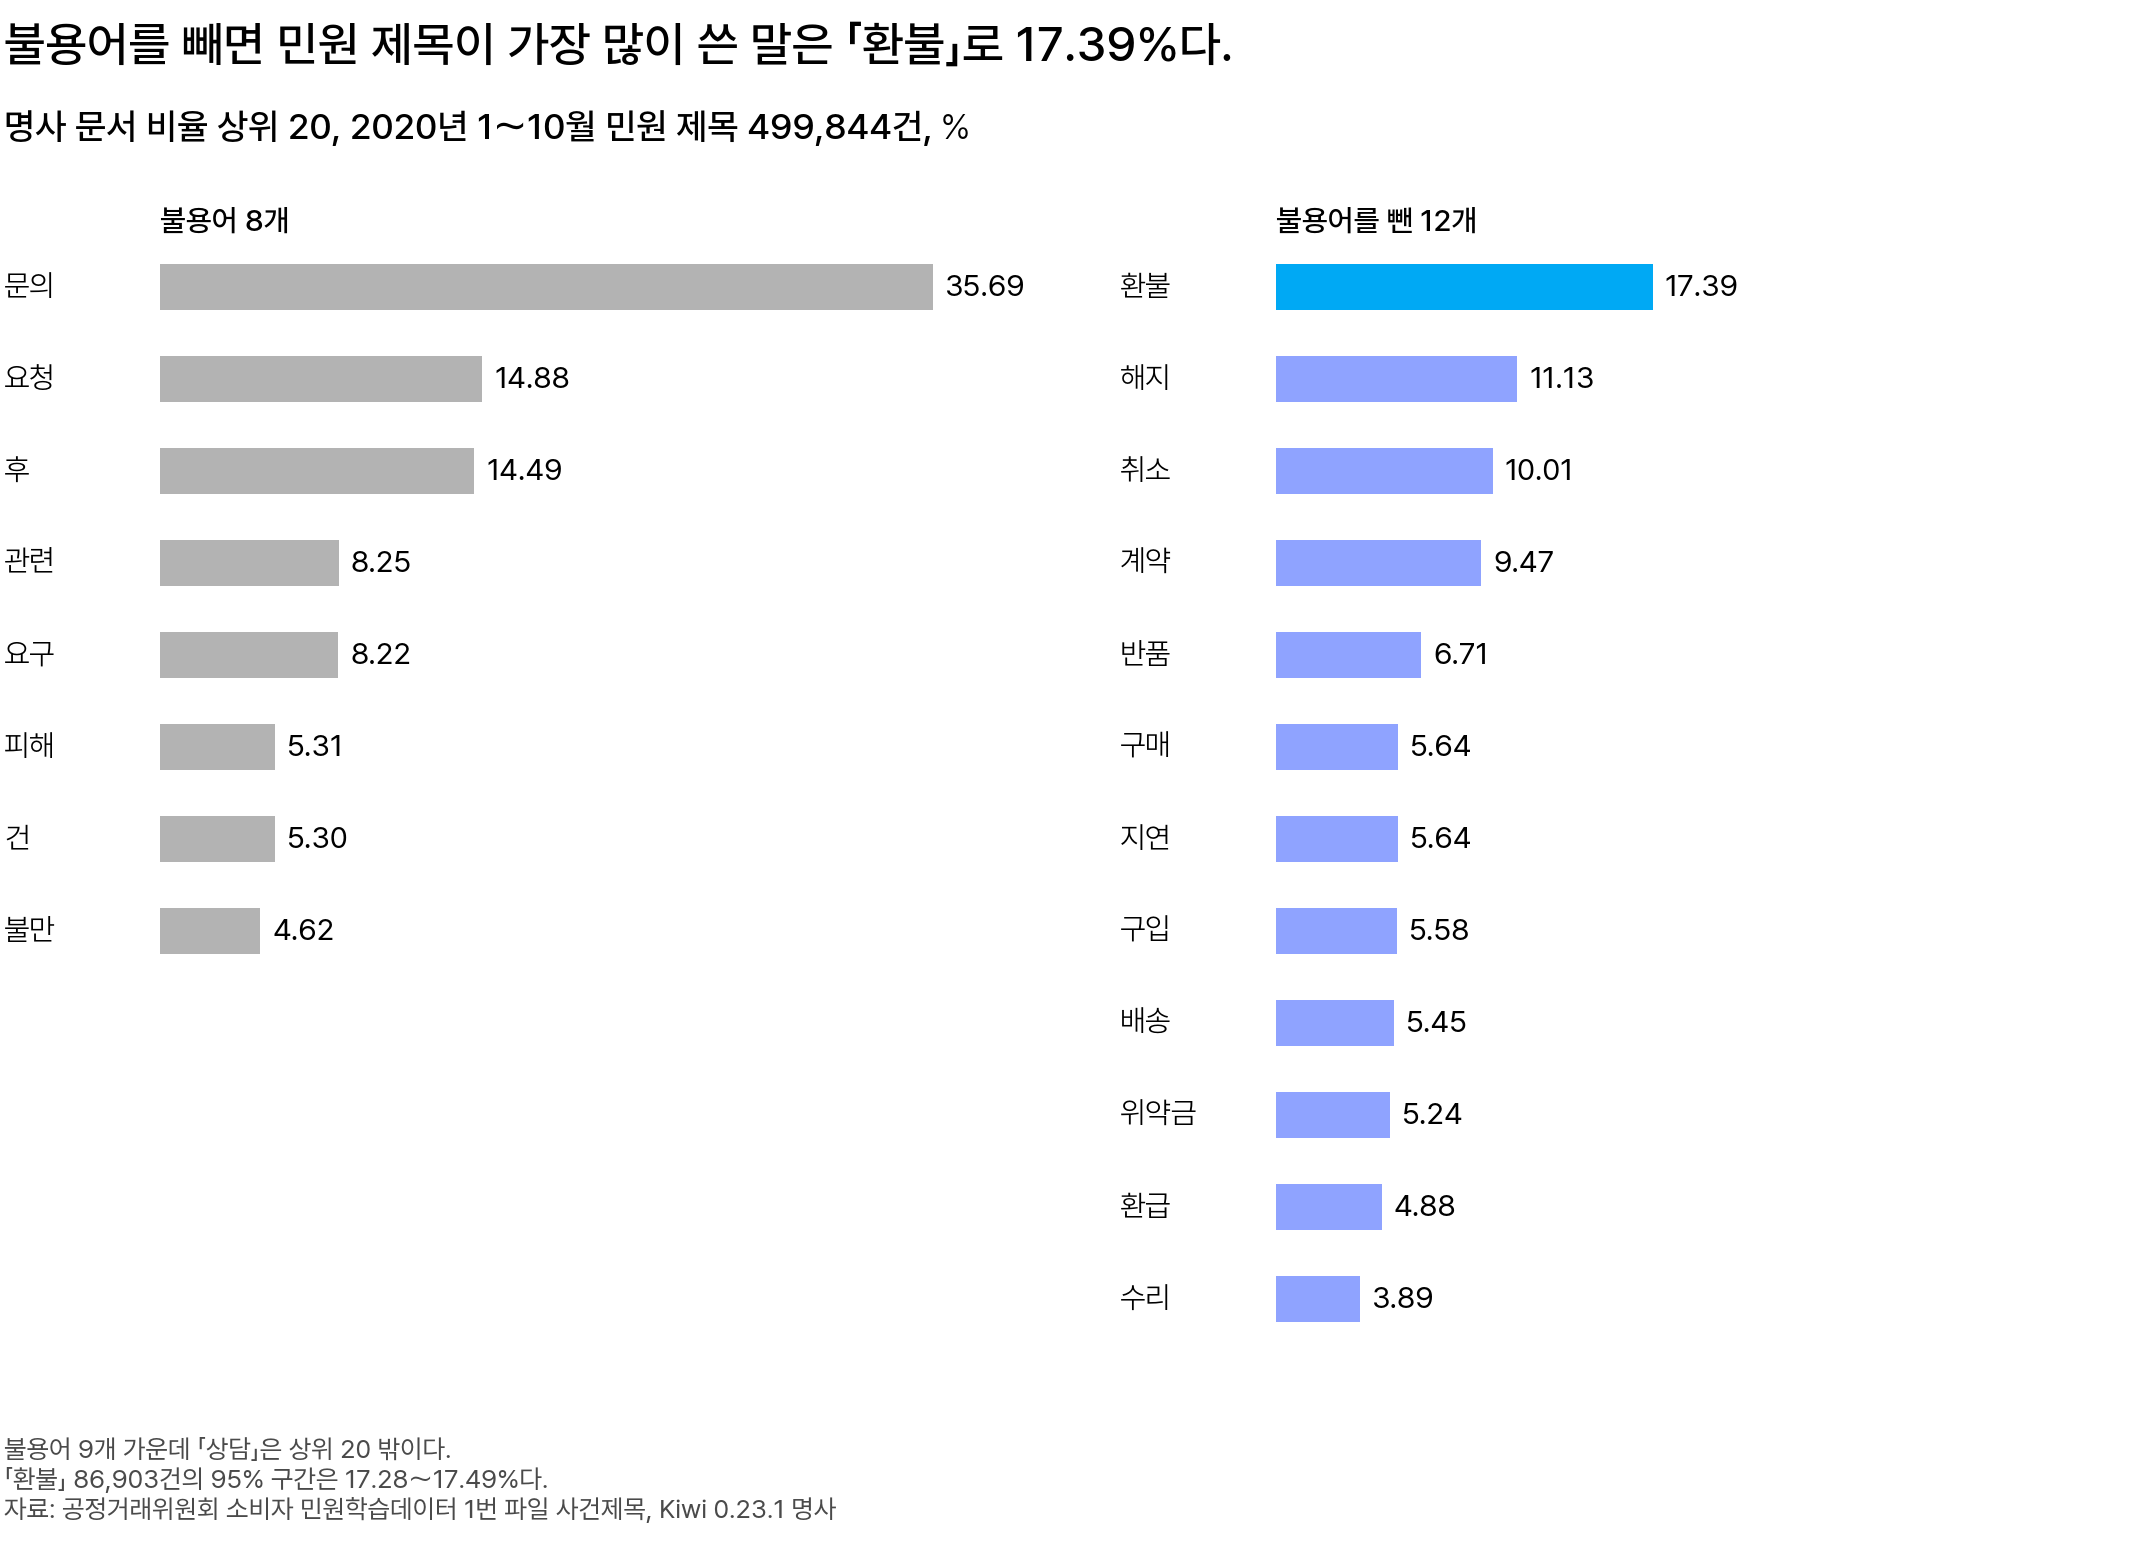

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 민원 제목 499,844건의 명사 문서 비율 상위 20. 왼쪽은 불용어 8개, 오른쪽은 불용어를 뺀 12개다. 두 그림은 막대 길이의 눈금이 같다</em></p>

17.39% 는 형태소 명사 「환불」을 쓴 제목의 비율입니다. 식에 대입하면 $\hat p_w = 86{,}903 \div 499{,}844 = 0.1739$ 이고, 95% 구간은 17.28～17.49% 입니다.

**집계 방식을 바꾼 차이도 구간에 들어 있나요?**

집계 방식을 바꿔 생기는 차이는 구간 계산에 들어 있지 않습니다. 이 구간은 집계 방식을 그대로 둘 때, 어떤 제목이 접수됐는가 하는 우연만 나타내기 때문입니다.

같은 50만 건도 어절 일치로 집계하면 10.30% 라서 17.39 − 10.30 = 7.09%p 달라집니다. 95% 구간은 17.39% 에서 위아래로 오차 한계 약 0.11%p 씩 넓힌 범위입니다. 7.09%p 는 그 60배가 넘습니다.

**맨 위 낱말은 불용어 목록에 따라 바뀌나요?**

상위 20 에서 불용어는 위 그림 왼쪽의 8개입니다. 1위가 무엇인지는 불용어 목록에 「문의」가 있는지에 달려 있습니다.

- 불용어를 하나도 빼지 않으면 1위는 「문의」 35.69% 이고 「환불」은 2위입니다.
- 「문의」 하나만 빼도, 9개를 모두 빼도 1위는 「환불」입니다.

**불용어를 뺀 나머지 낱말은 무엇을 말하나요?**

불용어를 뺀 나머지 12개 낱말은 3가지 주제로 나눠 볼 수 있습니다.

- 환불받거나 위약금을 내는 일: 환불 · 환급 · 위약금
- 계약을 끝내는 일: 해지 · 취소 · 계약
- 물건을 사고, 받고, 반품하고, 고치는 일: 구매 · 구입 · 배송 · 지연 · 반품 · 수리

다만 뜻이 거의 같은 두 쌍이 있습니다. 「구매」 5.64% 와 「구입」 5.58%, 「환불」과 「환급」 4.88% 입니다.

문서 비율은 낱말마다 구하므로, 같은 일을 다른 낱말로 쓴 제목은 따로 집계됩니다. 그래서 물건을 산 일을 말한 제목의 비율은 「구매」 한 낱말의 5.64% 보다 클 수 있습니다.

또 이 순위는 코로나가 퍼진 2020년 1～10월에 한합니다. 다른 해의 자료와 비교하지 않았으므로, 이 해에만 나타나는 순위인지는 이 자료로 말할 수 없습니다.

따라서 이 자료에서 가장 많이 나온 주제어는 「환불」입니다.

> 기간 · 집계 방식 · 불용어 목록이 바뀌면 1위와 비율도 달라질 수 있습니다.

### 어절로 집계하면 「해지」와 「위약금」의 순위가 바뀐다 [필수]

집계 방식이 달라도 많이 쓴 말의 순위는 그대로일 것 같습니다. 그런데 같은 50만 건도 어절 기준으로는 순위가 바뀌는 낱말이 있습니다. 아래 그림은 환불 · 해지 · 위약금 · 배송 · 취소 다섯 낱말의 문서 비율을 두 방식으로 구한 것입니다.

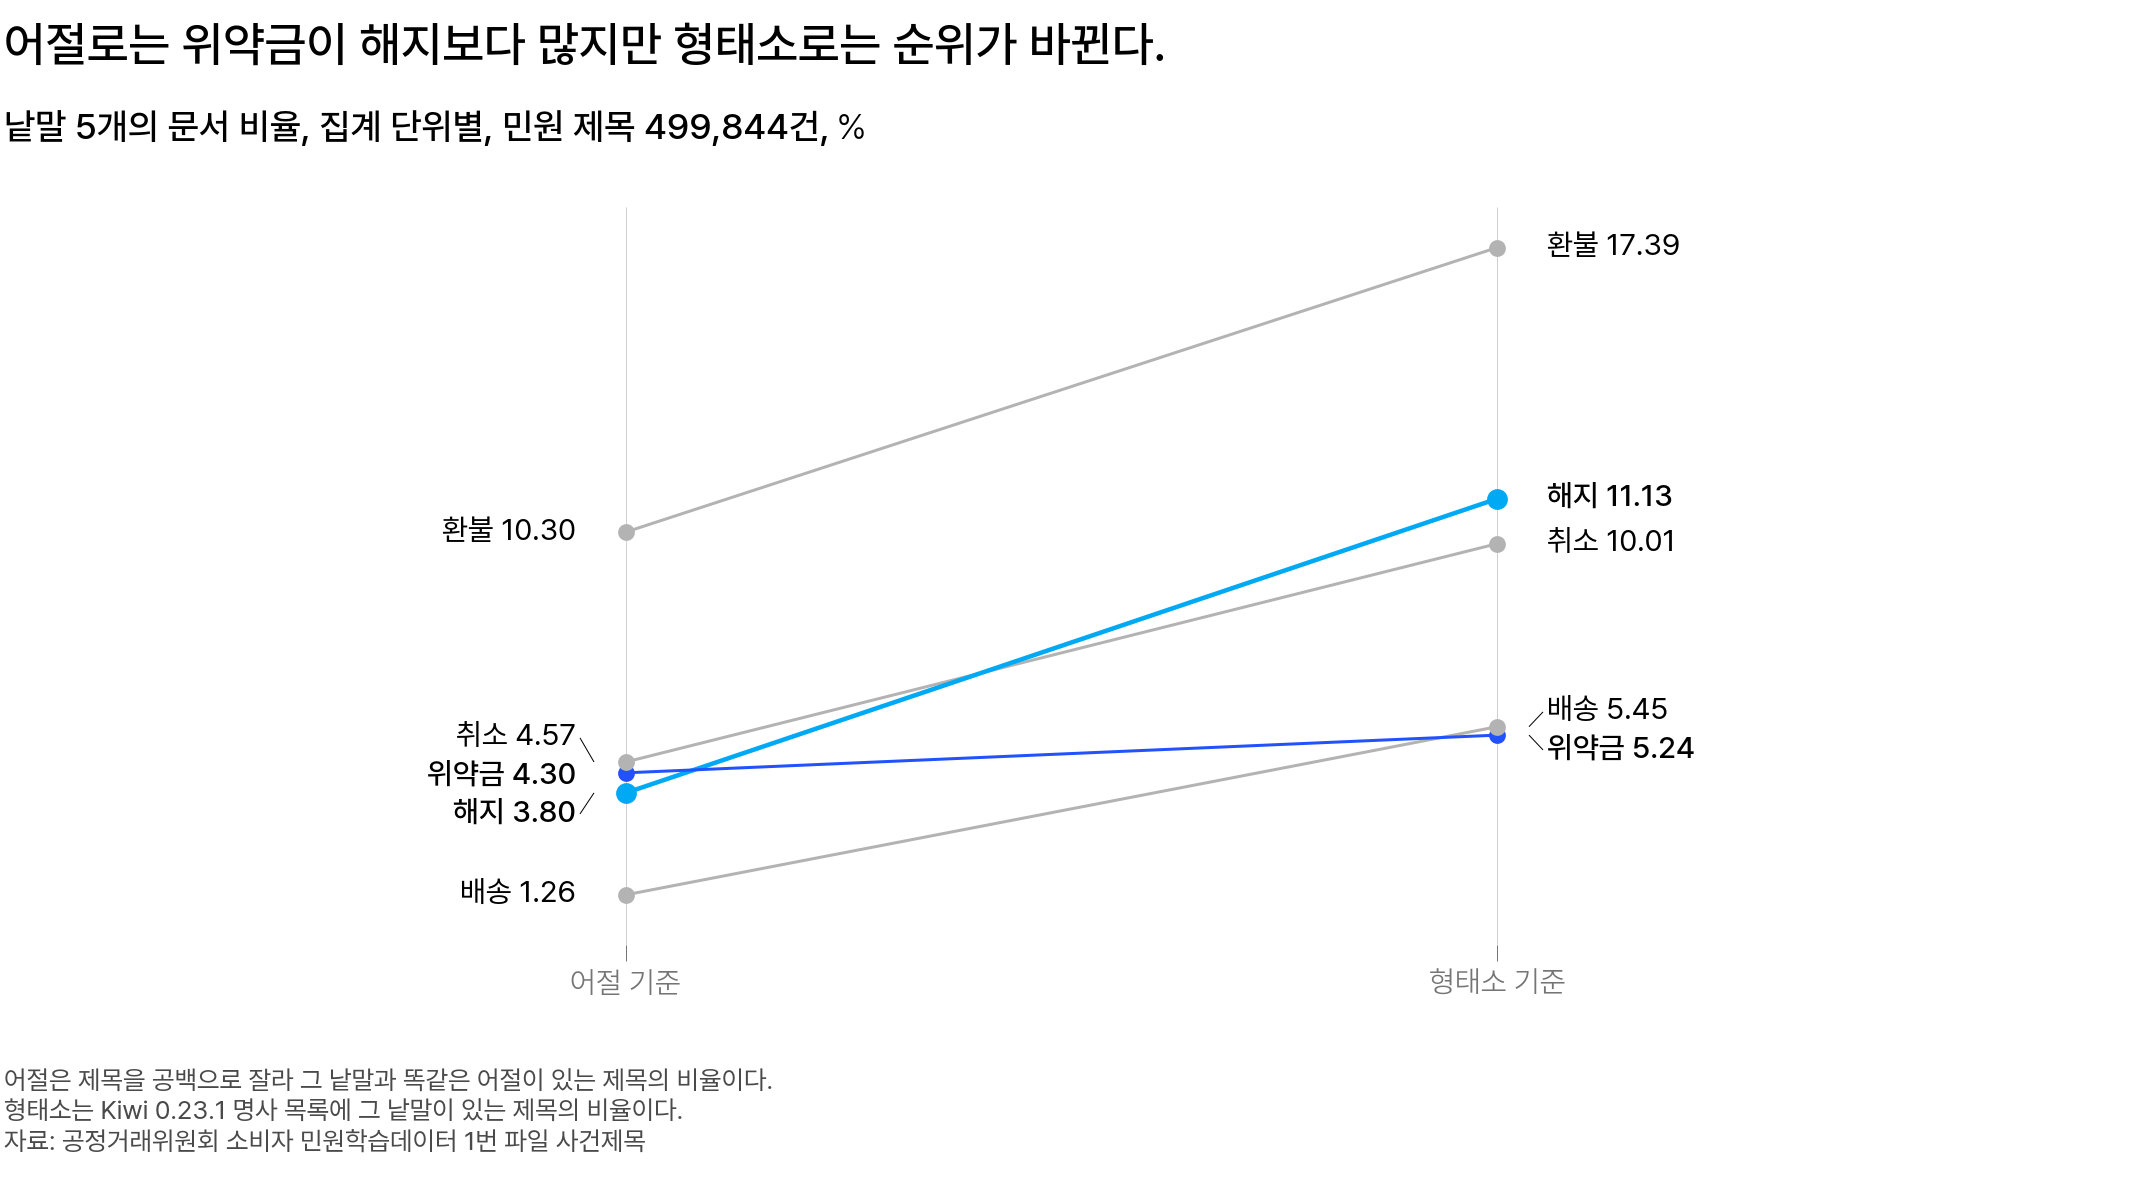

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 다섯 낱말의 문서 비율, 어절 기준과 형태소 기준. 선의 왼쪽 끝은 어절 기준, 오른쪽 끝은 형태소 기준의 문서 비율이다. 위로 갈수록 비율이 크다. 선 하나가 낱말 하나이고 하늘색 선이 해지, 파랑 선이 위약금이다. 어절로는 위약금이 앞서고 형태소로는 해지가 위약금의 두 배를 넘는다. 환불만 순위가 그대로다</em></p>

어절로는 위약금이 해지보다 큽니다. 형태소로는 반대로 해지가 위약금의 두 배를 넘습니다.

| 낱말 | 어절 기준 | 형태소 기준 |
|---|---:|---:|
| 해지 | 3.80% | 11.13% |
| 위약금 | 4.30% | 5.24% |
| 배송 | 1.26% | 5.45% |

**해지는 왜 크게 달라지나요?**

두 낱말 가운데 해지의 값이 크게 달라집니다.

- 「해지」는 「계약해지」 8,930건, 「중도해지」 3,424건처럼 다른 말과 한 어절로 쓴 제목이 많습니다. 그래서 형태소 기준 값이 어절 기준 값의 2.93배가 됩니다.
- 반면 「위약금」은 띄어 쓴 어절 그대로 나오는 제목이 대부분이라, 4.30% 에서 5.24% 로 조금 늘어납니다.

「배송」도 「배송지연으로」 · 「미배송」처럼 한 어절로 쓴 제목이 많아, 약 4.3배가 되어 위약금을 앞지릅니다. 해지도 취소를 앞지릅니다. 다섯 낱말 가운데 「환불」만 순위가 그대로입니다.

> 어절로 만든 표만 보면 「위약금 민원이 해지 민원보다 많다」는 틀린 결론에 이릅니다.

<div class="lms-summary">

**정리**

민원 제목을 형태소 명사로 집계하면 불용어를 뺀 1위는 「환불」입니다. 같은 제목도 어절 기준으로는 「해지」와 「위약금」의 순위가 바뀌어, 집계 방식이 결론을 바꿉니다.

**할 일**

- 문서 비율은 분모와 기간을 정해 구하고 95% 구간까지 계산합니다
- 어절 기준 표는 「계약해지」처럼 이어 쓴 제목을 빠뜨려 「해지」를 3분의 1쯤만 집계하므로 근거로 쓰지 않습니다

2020년 1～10월 민원 제목 499,844건의 17.39%(95% 구간 17.28～17.49%)가 「환불」을 썼습니다.

</div>

## 7. 정리와 팀 라운드

2020년 민원 제목은 무엇을 가장 많이 말할까요? 그 답은 수 하나로 충분할까요?

불용어를 뺀 1위는 「환불」 17.39% 입니다. 이 수는 원문 다섯 건과 같이 읽어야 뜻이 분명합니다.

### 낱말 표: 수와 원문 다섯 건 [필수]

텍스트를 문서 비율로 바꾸는 과정은 4단계이고 민원 제목은 잡음 정리를 건너뛰어 그 가운데 3개 단계를 거쳤습니다.

| 단계 | 처리 내용 | 민원 제목의 값 |
|---|---|---|
| 문자 인코딩 | 파일의 바이트를 글자로 읽는다 | cp949 |
| 잡음 정리 | 셋 이상 이어진 반복 자모는 두 글자만 남기고 자모 나열은 지운다 | 리뷰에만 쓰고 민원은 건너뜀 |
| 형태소 · 품사 선택 | 제목을 형태소로 자르고 명사만 남긴다 | 명사(NNG · NNP)만 |
| 문서-단어 행렬과 문서 비율 | 낱말마다 그 낱말이 있는 제목 수를 전체 제목 수로 나눈다 | 명사 30,798종, 1위 「환불」 |

핵심 질문의 답인 「환불」의 문서 비율은 문서-단어 행렬과 문서 비율 단계에서 나온 수입니다.

**수만으로는 무엇을 알 수 없나요?**

이 수만으로는 무엇에 대한 환불인지 알 수 없습니다. 문서 비율은 「환불」이 제목에 있는지만 따지기 때문입니다. 그래서 원문도 함께 봅니다.

「환불」 명사가 있는 제목 86,903건에서 무작위로 다섯 건(시드 0)을 뽑았습니다. 판매처 이름과 지역은 ○○ 로 바꿨습니다.

| 접수일 | 품목 | 사건제목 |
|---|---|---|
| 2020-05-21 | 국외여행 | ○○ 여행가입후 중도해지시 전액 환불받을수있나문의 |
| 2020-09-08 | 화장지(휴지) | 화장지 구매후 독한 화학향이 남으로 환불 요구 건 |
| 2020-07-30 | 국내결혼중개 | 새터민 결혼 중개 계약 환불 요청 관련 문의 |
| 2020-09-03 | 호텔 | 호흡기 증상으로 호텔 취소시 전액 환불 거부 |
| 2020-08-07 | 헬스장 | [질의] ○○ 소재(○○) 피트니스 환불불가 관련 문의의 件 |

다섯 건 모두 환불이 주제이지만 사연은 제각각입니다. 여행 중도 해지, 제품 불량, 중개 계약, 질병으로 인한 취소, 환불 불가 규정입니다.

> 문서 비율로는 「환불」을 말한 건수까지 알 수 있고, 무엇에 대한 환불인지는 원문을 읽어야 압니다.

**수와 원문을 한 표로 모으면 어떻게 되나요?**

아래 표는 질문마다 수와 근거 원문을 나란히 보여 줍니다. 다른 수와 비교해도 되는지는 분모 · 기간 · 분석 설정이 같은지로 정해지고, 이 표는 그 세 가지를 수와 한 줄에 보여 줍니다. 끝 열의 **분석 설정**은 이 수를 낸 분석기 버전 · 사전 · 품사 · 불용어입니다.

| 질문 | 분모 · 기간 | 수 | 95% 구간 | 근거 원문 | 분석 설정 |
|---|---|---|---|---|---|
| 민원 제목은 무엇을 가장 많이 말하는가 | 민원 제목 499,844건, 2020-01-01～10-17 | 「환불」 86,903건, 17.39% | 17.28～17.49% | 무작위 5건(위 표) | Kiwi 0.23.1 기본 사전, 명사만, 불용어 9개 제외 |

**이 수를 볼 때 무엇을 함께 확인하나요?**

이 수를 과신하지 않으려면 두 가지를 확인합니다.

- 수는 분석 설정에 따라 달라집니다. 사용자 사전을 더하거나 분석기 버전이 바뀌면 낱말마다 수가 조금씩 달라질 수 있습니다. 그래서 분석 설정이 다른 두 수는 바로 비교할 수 없습니다.
- 「환불」 명사가 있어도 환불을 다루지 않는 제목이 있습니다. 예를 들어 아래 제목이 그렇습니다.

> 「주식 정보업체에서 환불 받은 후 지급명령 독촉장 보내 문의」

이 제목에서 환불은 이미 끝난 일입니다. 제목은 지급명령 독촉장에 관해 묻습니다.

**「환불」이 있는 제목 가운데 실제로 환불을 다룬 비율은 얼마일까요?**

위 다섯 건은 모두 환불을 다뤘지만 다섯 건만으로는 이 비율을 약 48%～100% 로만 말할 수 있습니다(아래 그림). 환불을 다루지 않는 제목이 얼마나 되는지 말하려면 원문을 더 많이 무작위로 읽어야 합니다.

실제 비율이 48% 여도 다섯 건이 모두 환불을 다룰 확률은 0.48⁵ ≈ 2.5% 입니다. 그보다 낮은 비율만 지금 결과와 맞지 않는다고 봅니다.

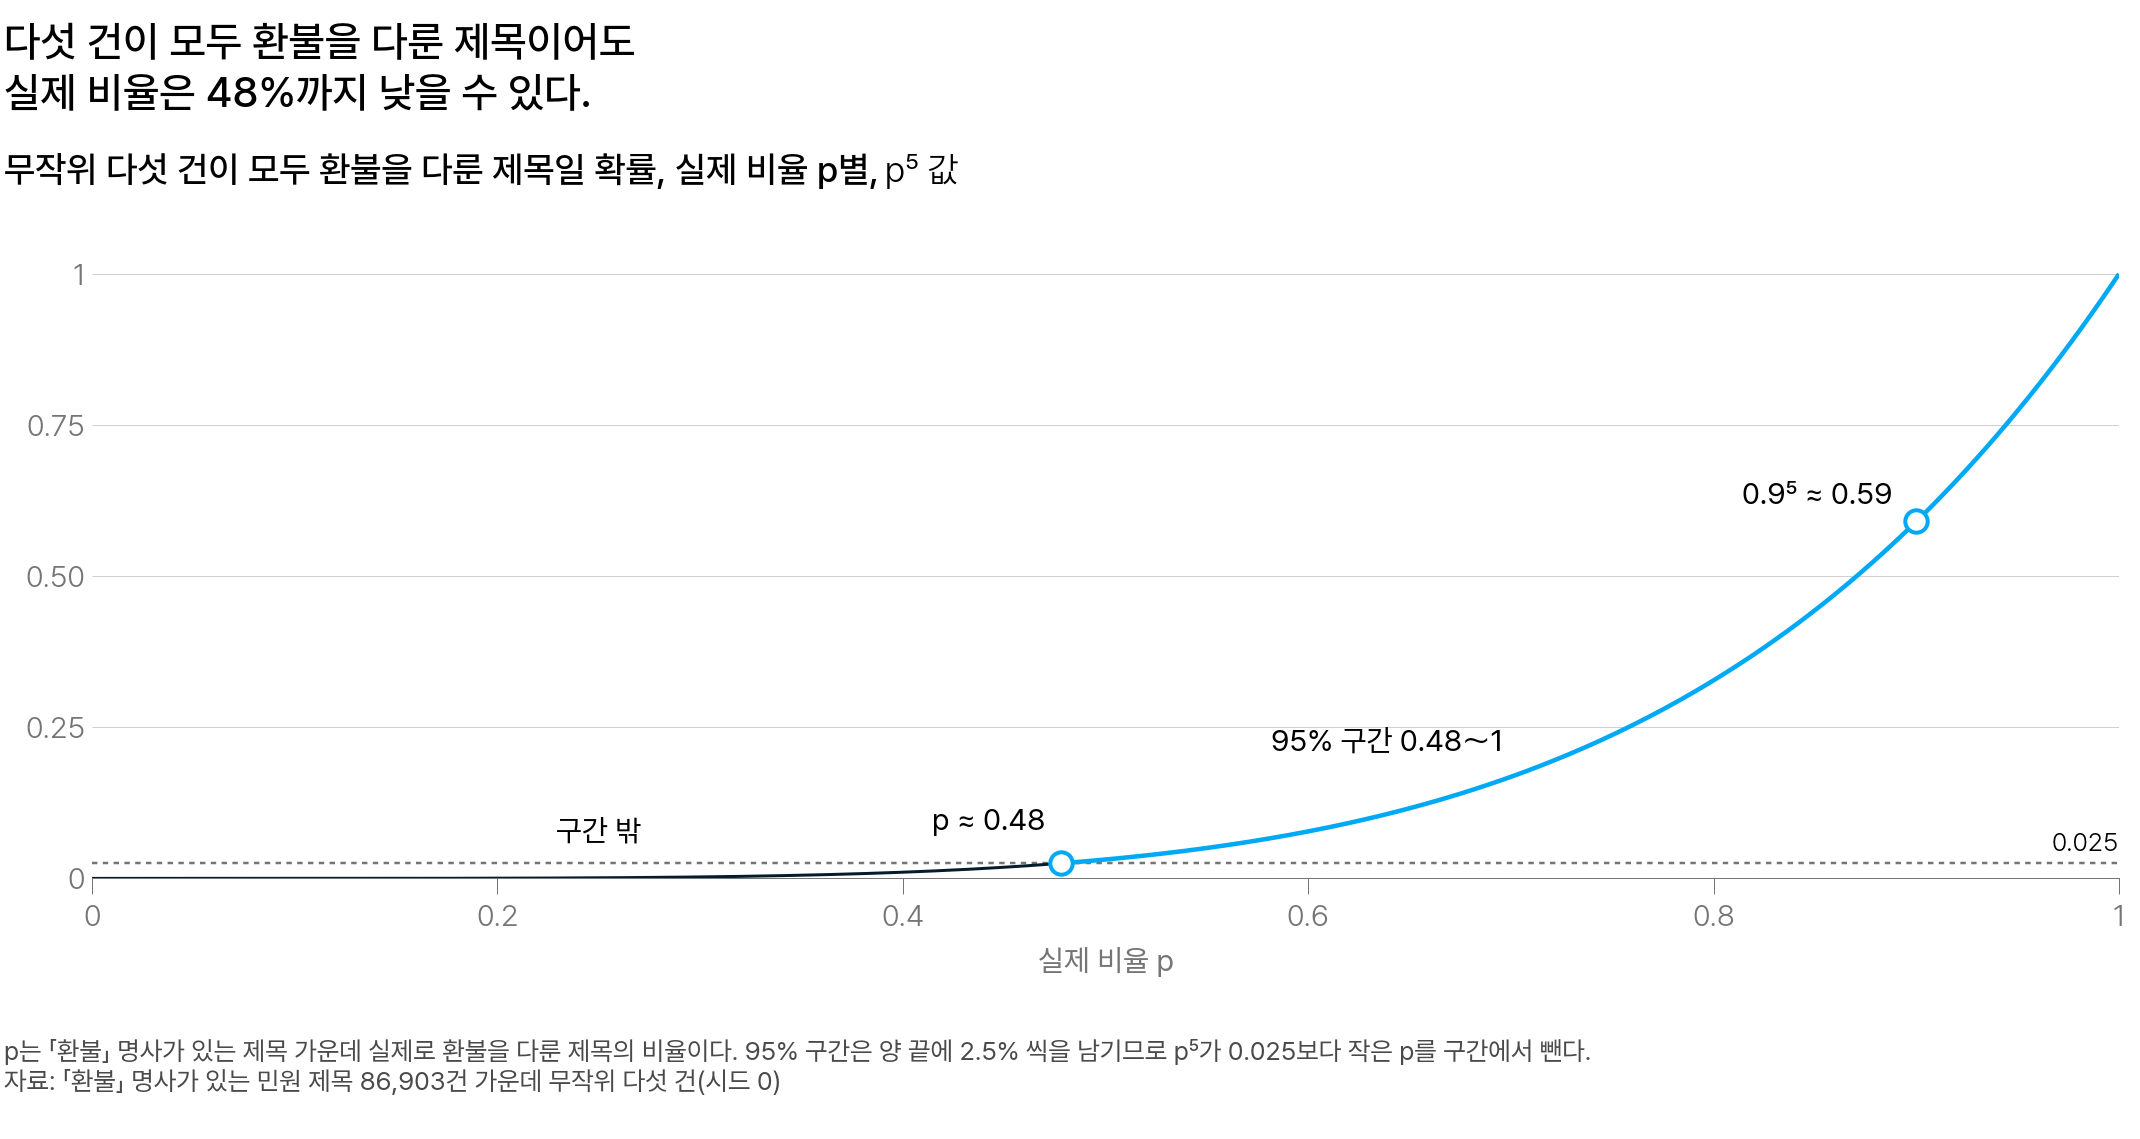

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 실제 비율 p, 세로축은 무작위 다섯 건이 모두 환불을 다룬 제목일 확률 p⁵ 이다. 곡선은 p ≈ 0.48 에서 회색 점선 0.025 와 만난다. p 가 0.48～1 인 하늘색 부분이 다섯 건으로 구한 95% 구간이다</em></p>

<details class="lms-extra"><summary>자세히 — 원문 다섯 건의 95% 구간(정확 구간)</summary>

다섯 건이 모두 환불을 다뤘으니, 이 다섯 건으로 추정한 비율은 1 입니다. 그런데 문서 비율의 구간 식에 대입하면 제곱근 안이 $1 \times (1 - 1) = 0$ 이라 오차 한계가 0 이 됩니다. 이처럼 건수가 적고 비율이 0 이나 1 에 가까우면 이 식은 쓸 수 없습니다.

그래서 다섯 건이 모두 환불을 다룬 제목일 확률 $p^5$ 를 직접 계산합니다. $p$ 는 「환불」이 있는 제목 가운데 실제로 환불을 다룬 제목의 비율입니다. 다섯 건은 서로 따로 무작위로 나오므로, 한 건이 환불을 다룬 제목일 확률 $p$ 를 다섯 번 곱합니다.

$n$ 건 가운데 몇 건이 환불을 다룰지의 확률을 **이항분포**라고 합니다. 다섯 건 모두일 확률 $p^5$ 는 그 가운데 하나입니다.

95% 구간은 결과가 기대보다 많이 나온 쪽 끝과 적게 나온 쪽 끝에 2.5% 씩을 남깁니다. 다섯 건이 모두 환불을 다룬 결과는 많이 나온 쪽 끝이라, 그쪽 2.5% 만 따집니다.

그래서 지금 결과가 100번에 2.5번보다 드물게 나오는 $p$ 를 구간에서 뺍니다. 이런 $p$ 에서는 $p^5$ 가 2.5% 보다 작습니다. 구간의 아래 끝은 이 확률이 2.5% 와 같아지는 비율이라, $p^5 = 0.025$ 를 풀면 됩니다. 양변의 다섯제곱근을 구해 소수 둘째 자리로 어림합니다.

$$
p = 0.025^{1/5} \approx 0.48
$$

확인하면 $0.48^5 \approx 2.5\%$ 입니다. 48% 보다 낮은 비율에서는 이 확률이 2.5% 보다 작아집니다. 위쪽 끝은 100% 입니다. 비율이 높을수록 이 확률은 커져서, 위쪽에는 뺄 비율이 없습니다.

예를 들어 실제 비율이 90% 라면 이 확률은 $0.9^5 \approx 0.59$ 로 흔한 일이라, 90% 는 구간 안에 있습니다. 이렇게 구한 구간을 정확 구간(Clopper–Pearson)이라고 합니다.

</details>

<div class="lms-summary">

**정리**

「환불」의 문서 비율은 그 말을 쓴 제목이 몇 건인지를 나타냅니다. 무엇에 대한 환불인지는 원문 다섯 건을 읽어야 알 수 있습니다. 같은 자료에서도 분석 설정에 따라 수가 달라질 수 있습니다.

**할 일**

- 원문은 무작위로 뽑아 읽고 다섯 건으로 구한 95% 구간 안에서만 말합니다

핵심 질문의 답은 「환불」 17.39% 라는 수와, 무엇에 대한 환불인지 보여 주는 원문 다섯 건입니다.

</div>

### 팀 라운드: 「피해」 · 「불만」을 불용어 목록에 둘 것인가 [필수]

아래 질문의 답은 수업에서 팀이 함께 정합니다. 지금은 자기 답과 근거만 적어 두면 됩니다.

각자 답과 확신도(1～5)를 적어 잠그면 팀의 답 분포가 공개됩니다. 근거 세 문장을 나눠 토론한 뒤 팀이 답 하나로 모아 제출합니다.

> **[문제] 팀 라운드: 키워드 표를 만들 때 「피해」 · 「불만」을 불용어 목록에 둘 것인가**
>
> 민원 담당 부서에 2020년 1～10월 민원 제목의 키워드 표를 보냅니다. 표는 불용어 9개를 집계한 뒤 빼고, 문서 비율 상위 10 을 보여 줍니다. 그런데 9개 가운데 「피해」와 「불만」은 「문의」 · 「건」과 달리 낱말에 뜻이 있습니다.
> 
> - **문서 수** 「피해」 26,544건(5.31%), 「불만」 23,090건(4.62%)입니다. 9개를 뺀 표의 10위 「위약금」은 26,182건(5.24%)입니다
> - **두 낱말을 목록에서 지운 순위** 「피해」 10위, 「위약금」 11위, 「불만」 13위
> - **「피해 구제」** 「피해」를 쓴 제목 가운데 9,091건(34.2%)은 명사 목록에서 「피해」 바로 뒤가 「구제」입니다. 「피해 구제」는 소비자가 한국소비자원에 피해 해결을 신청하는 제도의 이름입니다. 그래서 「피해구제 접수 후 진행사항 문의」처럼 신청한 뒤의 진행 상황을 묻는 제목에도 쓰입니다
> - **「불만」과 함께 있는 명사** 불용어를 빼면 지연 2,633 · 취소 2,516 · 환불 2,469 · 해지 2,403건 순입니다
> 
> 팀 안에서 의견이 3가지로 나뉘었습니다.
> 
> - **관점 A: 9개를 그대로 두고, 두 낱말의 문서 수는 표 아래에 함께 보여 준다.** 두 낱말만으로는 무슨 일의 민원인지 알 수 없다. 「불만」을 쓴 제목이 무슨 일인지는 함께 있는 지연 · 취소 · 환불 · 해지로 알 수 있다.
> - **관점 B: 두 낱말을 목록에서 지우고 표에 남긴다.** 두 낱말 모두 뜻이 있고, 「피해」 5.31% 는 10위 「위약금」 5.24% 보다 크다. 이 낱말을 「피해를 호소한 민원 5.31%」로 소개하면 소비자가 겪은 피해가 얼마나 많은지 드러난다.
> - **관점 C: 「피해 구제」를 바이그램(이웃한 두 낱말)이나 사용자 사전으로 떼어 낸 뒤, 원문을 읽고 정한다.** 한 낱말에 쓰임이 둘이면 수만으로는 정할 수 없다. 나머지 「피해」 제목에서 원문을 무작위로 뽑아 읽고 「피해」를 목록에 둘지 정하며, 「불만」은 목록에 둔다.
> 
> 자기 입장 하나와 근거 세 문장, 다음에 확인할 일 하나, 그리고 확신도를 정해 오세요.